# Patch entry / leave / opt-out states — `interpatch_shorten` curriculum from `full_net{0..4}`

Runs `load_patch_entry_exit_data` + `plot_patch_entry_exit_states` (copied verbatim from
`gru_networks_offset_exp_decay_dynamics_demo_evo.ipynb`) on the curriculum results produced by
`bash_scripts/train_curriculum_interpatch_shorten_full_nets.sh`.

In this curriculum both stages keep the same reward prefactors `[0, 0.6, 0.8]`; the only thing that
changes at stage 2 is `interpatch_len_decay_rate` (0.1 -> 0.4), which shortens the interpatch runs.
So unlike `high_becomes_low`, the reward structure is held fixed and the environment geometry is the
manipulated variable.

One analysis **per starting network** (net0–net4), each using **both** curriculum stages
(`step_00` + `step_01`). (Aggregating distinct networks into a single trajectory-PCA basis isn't
meaningful, so each network gets its own PCA/plot — set `COMBINE = True` in the last cell to instead
pool all nets into one basis.)


In [28]:
%load_ext autoreload
%autoreload 2

import os
os.environ["JAX_PLATFORM_NAME"] = "cpu"

# orbax 0.11.23's _get_internal_metadata calls bare asyncio.run(), which fails under a
# Jupyter kernel's already-running loop. Pinned to <0.11.24 because 0.11.24+ needs a
# jax.monitoring API absent in jax 0.5.x, so patch asyncio here instead.
import nest_asyncio
nest_asyncio.apply()
import sys
module_path = os.path.abspath(os.path.join('../..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from pathlib import Path
import jax

# Quiet absl's flax/orbax transformations-API deprecation warnings.
import logging
logging.getLogger('absl').setLevel(logging.ERROR)

import jax.numpy as jnp
from flax.training import checkpoints
from flax import serialization
from agents.a2c_rnn_flax import A2CRNNFlax, init_network_and_params
from environments.components.train_state import create_train_state
from environments.treadmill_env_jax import treadmill_session_default_params
import matplotlib.pyplot as plt
from nb_analysis_tools import load_trajectory_data, parse_behavioral_data
from aux_funcs import format_plot, format_pc_plot
import numpy as np
from sklearn.decomposition import PCA
import seaborn as sns
from copy import copy
from nb_dynamics_plotting import *
import glob
import re

plt.rcParams['font.family'] = 'Helvetica Light'

# All figures from this notebook live under one per-curriculum folder.
FIG_ROOT = '../../../figures/env_changes/interpatch_shorten'


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [29]:
# --- Patch entry / leave states: data loading (expensive; run once) ---
# For all trajectories, collect canonical patch-progress states:
#   entry blob = state entering a reward site (rsi -1 -> 1), one per patch (N-independent)
#   leave blob = state at rewards_seen_in_patch == N (& rsi == -1), for each N in
#                leave_rewards_range -> lets the plot sweep the leave threshold.
# rsi / rewards_seen_in_patch are observable to the agent one step late, so the hidden
# state is taken one timestep after the condition. Fit a 3-D PCA over all states, project
# them, and record for each the mean rewards collected in that patch type for that session
# (env). Returns a dict consumed by the plotting cell below (re-run that freely).
# Sessions are run through parse_behavioral_data so 'rewards_seen_in_patch' and
# 'reward_site_idx' are available.

def load_patch_entry_exit_data(all_trajs, leave_rewards_range=range(1, 12), max_files=None,
                               pca_points_per_session=1000):
    files = all_trajs if max_files is None else all_trajs[:max_files]
    rng = np.random.default_rng(0)
    leave_rewards_range = list(leave_rewards_range)

    pca_states = []                              # subsampled states for the PCA basis
    ah_pts, pt_pts, col_pts, kind_pts, n_pts, sess_pts, inst_pts = [], [], [], [], [], [], []
    sess_counter = 0
    for f in files:
        raw = load_trajectory_data(f)
        for e in range(len(raw)):               # each env == one session
            sess_id = sess_counter; sess_counter += 1
            d = parse_behavioral_data(raw[e])   # adds 'rewards_seen_in_patch', keeps 'reward_site_idx'
            ah = np.asarray(d['actor_hidden'])
            ainp = np.asarray(d['agent_in_patch']).astype(bool)
            pstart = np.asarray(d['current_patch_start'])
            ptype = np.asarray(d['current_patch_num']).astype(int)
            rsip = np.asarray(d['rewards_seen_in_patch']).astype(float)
            rsi = np.asarray(d['reward_site_idx']).astype(int)

            # States for the PCA basis (subsampled per session).
            if ah.shape[0] > pca_points_per_session:
                pca_states.append(ah[rng.choice(ah.shape[0], size=pca_points_per_session, replace=False)])
            else:
                pca_states.append(ah)

            # Patch instances via patch-start changes; collected reward + type per instance.
            inst = np.concatenate([[0], np.cumsum(np.diff(pstart) != 0)])   # (T,)
            n_inst = int(inst.max()) + 1
            inst_reward = np.zeros(n_inst)
            np.maximum.at(inst_reward, inst, rsip)                          # rewards collected in each patch
            inst_type = np.full(n_inst, -1, int); inst_type[inst] = ptype  # type const within instance
            inst_has = np.zeros(n_inst, bool); inst_has[inst[ainp]] = True  # instances the agent entered

            # Mean rewards collected per patch type for this session.
            type_mean = {}
            for t in np.unique(inst_type[inst_type >= 0]):
                m = (inst_type == t) & inst_has
                if m.any():
                    type_mean[int(t)] = float(inst_reward[m].mean())

            # +1 on the state index: rsi / rewards_seen_in_patch are not observable to the
            # agent until the next timestep.
            def _add(indices, kind, n_tag):
                for i in indices:
                    if i >= ah.shape[0]:
                        continue
                    t = int(ptype[i])
                    if t in type_mean:
                        ah_pts.append(ah[i]); pt_pts.append(t)
                        col_pts.append(type_mean[t]); kind_pts.append(kind); n_pts.append(n_tag)
                        sess_pts.append(sess_id)
                        inst_pts.append(sess_id * 1000000 + int(inst[i]))  # globally-unique patch id

            # entry = currently not in a reward site (rsi == -1), entering site idx 1 next step.
            entry_idx = np.where((rsi[:-1] == 0) & (np.concatenate([[-1], rsi[:-2]]) == -1))[0] + 1
            _add(entry_idx, 'entry', -1)

            # leave / 'exit' = has N rewards AND is ABOUT TO ENTER the next site (rsi -1 -> a site on
            # the next step), swept over the threshold range. This keeps only the inter-site state right
            # before the next site (not the whole inter-site gap), mirroring the 'entry' definition.
            about_to_enter = np.zeros(rsi.shape[0], dtype=bool)
            about_to_enter[:-1] = (rsi[:-1] == -1) & (rsi[1:] != -1)
            for N in leave_rewards_range:
                sel = np.where((np.rint(rsip).astype(int) == N) & about_to_enter)[0]
                if sel.size:
                    # ONE per patch instance: the FIRST about-to-enter after reaching N rewards, so
                    # 'exit' is one-per-patch (comparable to 'entry'/'optout'), not one-per-later-site.
                    _, first = np.unique(inst[sel], return_index=True)
                    sel = sel[first]
                _add(sel + 1, 'exit', int(N))

            # opt-out = last inter-site travel state (rsi == -1, in patch) within each
            # patch: the final rsi==-1 step before it reaches its last site and leaves.
            mask = ainp & (rsi == -1)
            optout_full = np.full(n_inst, -1, int)
            pos = np.where(mask)[0]
            optout_full[inst[pos]] = pos              # ascending pos -> last (max) per instance
            optout_idx = optout_full[optout_full >= 0] + 1
            _add(optout_idx, 'optout', -1)

    pca = PCA(n_components=3).fit(np.concatenate(pca_states, axis=0))
    return {
        'pcs': pca.transform(np.asarray(ah_pts)),   # (N, 3) entry/leave states in PC space
        'states': np.asarray(ah_pts),               # (N, hidden) raw actor_hidden at each state (for decoding)
        'pt_pts': np.asarray(pt_pts),               # patch type of each state
        'col_pts': np.asarray(col_pts),             # colour value (session/type mean rewards)
        'kind_pts': np.asarray(kind_pts),           # 'entry', 'exit', or 'optout'
        'n_pts': np.asarray(n_pts),                 # leave threshold N for 'exit' states (-1 for 'entry')
        'sess_pts': np.asarray(sess_pts),           # session id of each state (for grouped, leak-free CV)
        'inst_pts': np.asarray(inst_pts),           # globally-unique patch-instance id (to pair entry<->exit)
        'pca': pca,
        'pca_states': np.concatenate(pca_states, axis=0),   # subsampled actor_hidden used for the PCA basis
        'leave_rewards_range': leave_rewards_range,
    }


In [30]:
# --- Patch entry / leave / opt-out states in trajectory-PCA space (2D, stacked) ---
# Uses precomputed `entry_exit_data`. One figure per patch type: a grid of panels, one per
# leave threshold N (entry grey / opt-out black / leave-at-N autumn gradient) plus a final
# entry-vs-opt-out panel (entry winter / opt-out summer gradients). All panels share x/y
# limits; the legend (grey=entry, black=opt-out) and the 3 colourbars (entry, leave, opt-out
# gradients; colour = mean rewards collected in that patch type for that session) are shown
# once per figure. `ns` restricts which N to plot; `patch_types` the types.

from matplotlib.lines import Line2D

def plot_patch_entry_exit_states(data, ns=None, patch_types=(1, 2), max_points=None,
                                 ncols=4, panel_size=2.6):
    pcs = data['pcs']; pt_pts = data['pt_pts']
    col_pts = data['col_pts']; kind_pts = data['kind_pts']; n_pts = data['n_pts']
    if ns is None:
        ns = data['leave_rewards_range']
    rng = np.random.default_rng(0)

    kind_cmaps = {
        'entry':  sns.color_palette('winter', as_cmap=True),
        'exit':   sns.color_palette('autumn', as_cmap=True),
        'optout': sns.color_palette('summer', as_cmap=True),
    }
    kind_zorder = {'entry': 0, 'exit': 2, 'optout': 1}

    def _draw(ax, specs):
        # specs: list of (kind, idx, color); color=None -> reward gradient, else solid.
        for kind, idx, color in specs:
            if max_points is not None and idx.size > max_points:
                idx = rng.choice(idx, size=max_points, replace=False)
            if not idx.size:
                continue
            if color is None:
                ax.scatter(pcs[idx, 0], pcs[idx, 1], c=col_pts[idx], cmap=kind_cmaps[kind],
                           vmin=cvmin, vmax=cvmax, s=1, alpha=0.6, zorder=kind_zorder[kind])
            else:
                ax.scatter(pcs[idx, 0], pcs[idx, 1], color=color, s=1, alpha=0.6,
                           zorder=kind_zorder[kind])

    for t in patch_types:
        tidx = np.where(pt_pts == t)[0]
        if tidx.size == 0:
            continue
        cvmin, cvmax = float(col_pts[tidx].min()), float(col_pts[tidx].max())
        # equal scale on both axes: span the SAME data range on x and y (pad the shorter axis with
        # white space), centred, so set_aspect('equal') below renders each panel roughly square.
        x0, x1 = float(pcs[tidx, 0].min()), float(pcs[tidx, 0].max())
        y0, y1 = float(pcs[tidx, 1].min()), float(pcs[tidx, 1].max())
        half = 0.5 * (max(x1 - x0, y1 - y0) or 1) * 1.05
        cx, cy = 0.5 * (x0 + x1), 0.5 * (y0 + y1)
        xlim = (cx - half, cx + half)
        ylim = (cy - half, cy + half)

        entry_idx = np.where((pt_pts == t) & (kind_pts == 'entry'))[0]
        optout_idx = np.where((pt_pts == t) & (kind_pts == 'optout'))[0]

        # entry / opt-out panel first, then the leave-at-N sweep.
        panels = [('entry / opt-out',
                   [('entry', entry_idx, None), ('optout', optout_idx, None)])]
        for N in ns:
            leave_idx = np.where((pt_pts == t) & (kind_pts == 'exit') & (n_pts == N))[0]
            panels.append((f'{N} reward' + ('s' if N > 1 else ''),
                           [('entry', entry_idx, 'grey'), ('optout', optout_idx, 'black'),
                            ('exit', leave_idx, None)]))

        n_panels = len(panels)
        nrows = int(np.ceil(n_panels / ncols))
        fig = plt.figure(figsize=(ncols * panel_size + 2.6, nrows * panel_size + 0.4))
        gs = fig.add_gridspec(nrows, ncols, left=0.05, right=0.80, top=0.92, bottom=0.07,
                              hspace=0.35, wspace=0.25)
        for p, (subtitle, specs) in enumerate(panels):
            r, c = divmod(p, ncols)
            ax = fig.add_subplot(gs[r, c])
            _draw(ax, specs)
            ax.set_xlim(xlim); ax.set_ylim(ylim)
            ax.set_aspect('equal', adjustable='box')   # equal x/y scale -> square panels
            ax.set_title(subtitle, fontsize=14)
            ax.tick_params(labelsize=6)
            if r != nrows - 1:
                ax.set_xticklabels([])
            else:
                ax.set_xlabel('PC1', fontsize=7)
            if c != 0:
                ax.set_yticklabels([])
            else:
                ax.set_ylabel('PC2', fontsize=7)
            format_plot(ax)
        fig.suptitle(f'Patch type {t}', fontsize=14)

        # Shared legend (solid grey/black kinds) shown once.
        handles = [
            Line2D([0], [0], marker='o', linestyle='none', markerfacecolor='grey',
                   markeredgecolor='grey', label='before second site'),
            Line2D([0], [0], marker='o', linestyle='none', markerfacecolor='black',
                   markeredgecolor='black', label='before opt-out'),
        ]
        fig.legend(handles=handles, fontsize=8, loc='upper left',
                   bbox_to_anchor=(0.82, 0.92), frameon=False)

        # All 3 gradient colourbars shown once.
        cbars = [('entry', 'before second site'), ('exit', 'accumulated N rewards'),
                 ('optout', 'before opt-out')]
        for i, (kind, label) in enumerate(cbars):
            cax = fig.add_axes([0.86, 0.10 + i * 0.24, 0.015, 0.17])
            sm = plt.cm.ScalarMappable(cmap=kind_cmaps[kind], norm=plt.Normalize(cvmin, cvmax))
            sm.set_array([])
            cb = fig.colorbar(sm, cax=cax)
            cax.set_title(label)
            cb.set_label('Rewards per patch\nin session')
            cax.tick_params(labelsize=6)
            format_plot(cax)

In [31]:
# Variance-explained (scree) plot: fit a FULL-rank PCA on the same subsampled actor_hidden states
# used for the entry/exit PCA basis, and show per-component + cumulative variance. The first `n_used`
# components (highlighted) are the ones the entry/exit plots actually use.
def plot_variance_explained(data, n_show=15, n_used=3, title=None):
    X = data['pca_states']                       # (n_points, hidden_size)
    k = min(X.shape[1], max(n_show, n_used))
    evr = PCA(n_components=k).fit(X).explained_variance_ratio_
    cum = np.cumsum(evr)
    comps = np.arange(1, len(evr) + 1)

    fig, ax = plt.subplots(figsize=(5, 3.2))
    ax.bar(comps, evr, color=['C0' if c <= n_used else '0.78' for c in comps],
           label='per component')
    ax.plot(comps, cum, '-o', color='C3', ms=3, lw=1, label='cumulative')
    ax.axhline(cum[n_used - 1], color='C0', ls='--', lw=1, alpha=0.7)
    ax.text(comps[-1], cum[n_used - 1] - 0.03, f'{cum[n_used-1]*100:.0f}% in {n_used} PCs',
            va='top', ha='right', fontsize=8, color='C0')
    ax.set_xlabel('Principal component'); ax.set_ylabel('Fraction of variance explained')
    ax.set_xticks(comps); ax.set_ylim(0, 1.02)
    if title:
        ax.set_title(title)
    ax.legend(fontsize=8, frameon=False, loc='center right')
    format_plot(ax)
    return evr


In [32]:
# Curriculum results: one trajectory list per starting network, spanning BOTH curriculum stages
# (step_00 + step_01) via the step_* glob. Paths are relative to code/notebooks/bulk_runs_jax/.
import glob, re

NETS = [0, 1, 2, 3, 4]
RESULTS_ROOT = '../../../results'
EXP_TMPL = 'fixed_exp_gru_initial_prob_offset_interpatch_shorten_full_net{i}'

def net_trajectories(i):
    base = f'{RESULTS_ROOT}/{EXP_TMPL.format(i=i)}'
    return sorted(
        glob.glob(f'{base}/step_*/traj_*.pkl'),
        key=lambda p: int(re.search(r'traj_(\d+)\.pkl$', p).group(1)),
    )

COMBINE = False  # True -> pool all nets into one trajectory-PCA basis (single plot)

if COMBINE:
    all_trajs = [f for i in NETS for f in net_trajectories(i)]
    print(f'ALL nets combined: {len(all_trajs)} trajectories (step_00 + step_01)')
    entry_exit_data = load_patch_entry_exit_data(all_trajs)
    plot_patch_entry_exit_states(entry_exit_data)
    plot_variance_explained(entry_exit_data, title='all nets combined')
    plt.show()
else:
    for i in NETS:
        trajs = net_trajectories(i)
        print(f'=== full_net{i}: {len(trajs)} trajectories (step_00 + step_01) ===')
        entry_exit_data = load_patch_entry_exit_data(trajs)
        plot_patch_entry_exit_states(entry_exit_data)
        plot_variance_explained(entry_exit_data, title=f'full_net{i}')
        plt.show()


=== full_net0: 30 trajectories (step_00 + step_01) ===


KeyboardInterrupt: 

## Linear decoders: session mean rewards collected, from the actor state

For each starting network we fit **ridge linear decoders** predicting the session x patch-type mean
rewards collected (`col_pts` -- the value colouring the plots above) from the raw 64-D actor-GRU
state, at three points:
1. **before first site** -- entering the patch's first reward site,
2. **after 1 reward** -- the inter-site gap after collecting 1 reward, before the next site,
3. **before opt-out** -- the last inter-site state before leaving the patch.

Decoders are fit **per patch type** (1, 2) to avoid the trivial patch-type -> reward confound, and use
**session-grouped** cross-validation (`GroupKFold`) so a session's states never straddle train/test
(every state in a session shares the same target). To keep long / reward-rich sessions from
dominating, each session is **randomly undersampled** to a common number of states (the smallest
per-session count in the subset) before fitting -- which, since each session carries one target value,
also balances the target distribution. Bars = mean cross-validated R^2 across net0-net4; dots =
individual networks.

In [ ]:
# Load trajectory data for all networks once; all downstream decoder cells read from here.
PATCH_TYPES = (1, 2)
print('Loading trajectory data for all nets...')
net_data = {}
for i in NETS:
    print(f'  net{i}...', end=' ', flush=True)
    net_data[i] = load_patch_entry_exit_data(net_trajectories(i))
    print('done')
print('All nets loaded.')


Loading trajectory data for all nets...
  net0... done
  net1... done
  net2... done
  net3... done
  net4... done
All nets loaded.


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, GroupKFold

# 8 decoding conditions:
#   (1) before first site  (2) before opt-out
#   (3-5) after 1/2/3 rewards  (6-8) after 1/2/3 rewards - before first site (displacement)
DECODE_CONDITIONS = {
    'before first site': lambda d: d['kind_pts'] == 'entry',
    'before opt-out':    lambda d: d['kind_pts'] == 'optout',
    'after 1 reward':    lambda d: (d['kind_pts'] == 'exit') & (d['n_pts'] == 1),
    'after 2 rewards':   lambda d: (d['kind_pts'] == 'exit') & (d['n_pts'] == 2),
    'after 3 rewards':   lambda d: (d['kind_pts'] == 'exit') & (d['n_pts'] == 3),
}
DIFF_NS = (1, 2, 3,)   # displacement conditions: exit@N - entry, for each N

def _undersample_by_session(sess, k, seed=0):
    rng = np.random.default_rng(seed)
    keep = []
    for s in np.unique(sess):
        idx = np.where(sess == s)[0]
        keep.append(idx if idx.size <= k else rng.choice(idx, size=k, replace=False))
    return np.concatenate(keep)

def _fit_decoder_cv(X, y, g, cv, alpha, undersample, us_per_session, us_seed, kernel=None):
    """Session-grouped CV decoding. kernel=None -> Ridge (linear); kernel='rbf' etc -> KernelRidge."""
    n = X.shape[0]; n_sess = int(np.unique(g).size); k = None
    if undersample and n_sess > 0:
        counts = np.unique(g, return_counts=True)[1]
        k = int(counts.min()) if us_per_session is None else int(us_per_session)
        su = _undersample_by_session(g, k=k, seed=us_seed)
        X, y, g = X[su], y[su], g[su]
    n_used = X.shape[0]
    if n_sess >= cv and np.ptp(y) > 1e-9:
        if kernel is None:
            model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        else:
            model = make_pipeline(StandardScaler(), KernelRidge(alpha=max(alpha, 1e-6), kernel=kernel))
        r2 = float(np.mean(cross_val_score(model, X, y, groups=g, cv=GroupKFold(cv), scoring='r2')))
    else:
        r2 = np.nan
    return dict(n=n, n_used=n_used, per_session=k, n_sess=n_sess, cv_r2=r2)

def decode_reward_cv(data, patch_types=(1, 2), cv=5, alpha=1.0,
                     undersample=True, us_per_session=None, us_seed=0,
                     diff_Ns=DIFF_NS, kernel=None):
    """Decode col_pts from the actor state across 8 conditions.
    kernel=None -> Ridge; kernel='rbf' etc -> KernelRidge."""
    X_all, y_all, pt, sess = data['states'], data['col_pts'], data['pt_pts'], data['sess_pts']
    kp, npt, inst = data['kind_pts'], data['n_pts'], data['inst_pts']
    out = []
    for cond, sel in DECODE_CONDITIONS.items():
        base = sel(data)
        for t in patch_types:
            m = base & (pt == t)
            out.append(dict(condition=cond, patch_type=t,
                            **_fit_decoder_cv(X_all[m], y_all[m], sess[m],
                                              cv, alpha, undersample, us_per_session, us_seed, kernel)))
    for diff_N in diff_Ns:
        for t in patch_types:
            e_by = {int(inst[j]): j for j in np.where((kp == 'entry') & (pt == t))[0]}
            pairs = [(e_by[int(inst[j])], j)
                     for j in np.where((kp == 'exit') & (npt == diff_N) & (pt == t))[0]
                     if int(inst[j]) in e_by]
            if pairs:
                er = np.array([a for a, _ in pairs]); xr = np.array([b for _, b in pairs])
                r = _fit_decoder_cv(X_all[xr] - X_all[er], y_all[xr], sess[xr],
                                    cv, alpha, undersample, us_per_session, us_seed, kernel)
            else:
                r = dict(n=0, n_used=0, per_session=None, n_sess=0, cv_r2=np.nan)
            n_str = 's' if diff_N > 1 else ''
            out.append(dict(condition=f'after {diff_N} reward{n_str} − entry', patch_type=t, **r))
    return out

PT_COLORS = {2: '#E1812C', 1: '#3A9E78'}

def plot_decoder_results(results, cond_order, title, patch_types=(1, 2)):
    """Consolidated decoder plot: both patch types on one axes, colored by type.
    Individual points = open circles (low alpha); group mean = solid dot + SEM error bar."""
    n_cond = len(cond_order)
    pt_offset = {1: -0.13, 2: 0.13}
    fig, ax = plt.subplots(figsize=(4, 3))
    rng = np.random.default_rng(0)
    for xi, cond in enumerate(cond_order):
        for t in patch_types:
            vals = np.array([r['cv_r2'] for r in results
                             if r['patch_type'] == t and r['condition'] == cond
                             and not np.isnan(r['cv_r2'])])
            if not vals.size:
                continue
            color = PT_COLORS[t]
            xpos = xi + pt_offset[t]
            jitter = rng.uniform(-0.06, 0.06, vals.size)
            ax.scatter(xpos + jitter, vals, s=22, facecolors='none', edgecolors=color,
                       linewidths=0.8, alpha=0.35, zorder=2)
            mean = vals.mean()
            sem = vals.std(ddof=1) / np.sqrt(vals.size) if vals.size > 1 else 0
            ax.errorbar(xpos, mean, yerr=sem, fmt='o', color=color, ms=3,
                        capsize=3, capthick=1, linewidth=1.2, zorder=3,
                        label=f'patch type {t}' if xi == 0 else None)
    ax.axhline(0, color='k', lw=0.8, zorder=1)
    ax.set_xticks(range(n_cond))
    ax.set_xticklabels(cond_order, rotation=30, ha='right', fontsize=7)
    ax.set_ylabel('Cross-validated $R^2$', fontsize=9)
    ax.set_title(title, fontsize=11)
    format_plot(ax)
    fig.tight_layout()
    plt.show()


net0 | type 1 | before first site | CV R^2 = +0.282
net0 | type 2 | before first site | CV R^2 = +0.246
net0 | type 1 | before opt-out    | CV R^2 = +0.227
net0 | type 2 | before opt-out    | CV R^2 = +0.103
net0 | type 1 | after 1 reward    | CV R^2 = +0.443
net0 | type 2 | after 1 reward    | CV R^2 = +0.338
net0 | type 1 | after 2 rewards   | CV R^2 = +0.447
net0 | type 2 | after 2 rewards   | CV R^2 = +0.353
net0 | type 1 | after 3 rewards   | CV R^2 = +0.459
net0 | type 2 | after 3 rewards   | CV R^2 = +0.364
net0 | type 1 | after 1 reward − entry | CV R^2 = +0.234
net0 | type 2 | after 1 reward − entry | CV R^2 = +0.181
net0 | type 1 | after 2 rewards − entry | CV R^2 = +0.291
net0 | type 2 | after 2 rewards − entry | CV R^2 = +0.228
net0 | type 1 | after 3 rewards − entry | CV R^2 = +0.348
net0 | type 2 | after 3 rewards − entry | CV R^2 = +0.267
net1 | type 1 | before first site | CV R^2 = +0.248
net1 | type 2 | before first site | CV R^2 = +0.261
net1 | type 1 | before opt-out

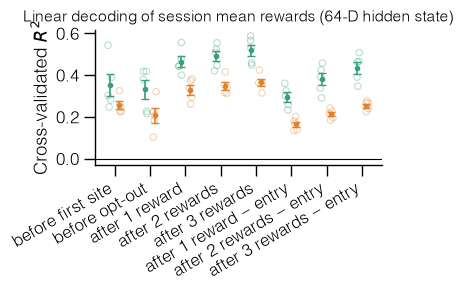

In [ ]:
decode_results = []
for i in NETS:
    d = net_data[i]
    for row in decode_reward_cv(d, patch_types=PATCH_TYPES, alpha=0, undersample=False):
        decode_results.append(dict(net=i, **row))
        r2s = f"{row['cv_r2']:+.3f}" if not np.isnan(row['cv_r2']) else ' n/a '
        print(f"net{i} | type {row['patch_type']} | {row['condition']:<17} | CV R^2 = {r2s}")

COND_ORDER = list(dict.fromkeys(r['condition'] for r in decode_results))
plot_decoder_results(decode_results, COND_ORDER,
                     'Linear decoding of session mean rewards (64-D hidden state)')


sigma=0.0: done
sigma=0.05: done
sigma=0.1: done


/tmp/ipykernel_159715/1226180190.py:109: UserWarning: Glyph 963 (\N{GREEK SMALL LETTER SIGMA}) missing from font(s) Helvetica Light.
  fig.tight_layout()
/home/david.bell/work/favorably_connected_2/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 963 (\N{GREEK SMALL LETTER SIGMA}) missing from font(s) Helvetica Light.
  fig.canvas.print_figure(bytes_io, **kw)


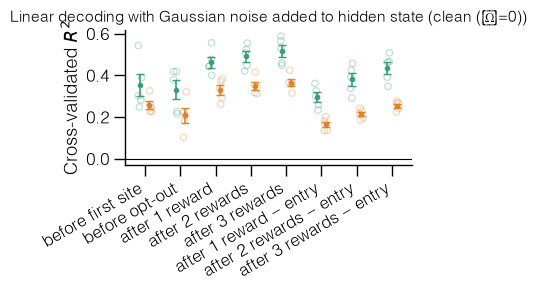

/tmp/ipykernel_159715/1226180190.py:109: UserWarning: Glyph 963 (\N{GREEK SMALL LETTER SIGMA}) missing from font(s) Helvetica Light.
  fig.tight_layout()
/home/david.bell/work/favorably_connected_2/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 963 (\N{GREEK SMALL LETTER SIGMA}) missing from font(s) Helvetica Light.
  fig.canvas.print_figure(bytes_io, **kw)


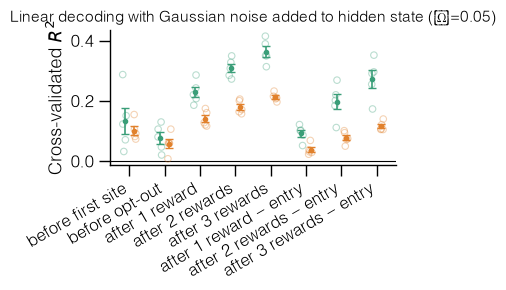

/tmp/ipykernel_159715/1226180190.py:109: UserWarning: Glyph 963 (\N{GREEK SMALL LETTER SIGMA}) missing from font(s) Helvetica Light.
  fig.tight_layout()
/home/david.bell/work/favorably_connected_2/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 963 (\N{GREEK SMALL LETTER SIGMA}) missing from font(s) Helvetica Light.
  fig.canvas.print_figure(bytes_io, **kw)


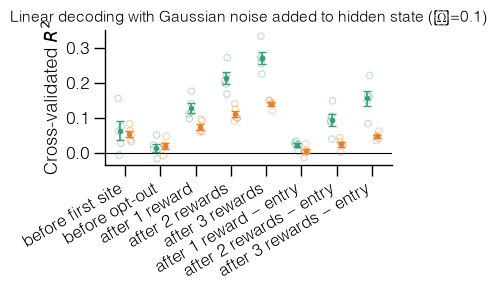

In [ ]:
# Linear decoding with Gaussian noise added to all hidden-state components.
# GRU hidden states are tanh-bounded in (-1, 1), so SD=0.1 / 0.5 is ~10% / 50% of range.
NOISE_SIGMAS = [0.0, 0.05, 0.1]   # <-- adjust as needed
NOISE_SEED = 42

results_by_sigma = {}
for sigma in NOISE_SIGMAS:
    rows = []
    rng = np.random.default_rng(NOISE_SEED)
    for i in NETS:
        d = net_data[i]
        noisy_states = d['states'] + rng.normal(0, sigma, d['states'].shape) if sigma > 0 else d['states']
        d_noisy = {**d, 'states': noisy_states}
        for row in decode_reward_cv(d_noisy, patch_types=PATCH_TYPES, alpha=0, undersample=False):
            rows.append(dict(net=i, sigma=sigma, **row))
    results_by_sigma[sigma] = rows
    print(f'sigma={sigma}: done')

COND_ORDER_NOISE = list(dict.fromkeys(r['condition'] for r in results_by_sigma[0.0]))
for sigma in NOISE_SIGMAS:
    lbl = 'clean (\u03c3=0)' if sigma == 0 else f'\u03c3={sigma}'
    plot_decoder_results(results_by_sigma[sigma], COND_ORDER_NOISE,
                         f'Linear decoding with Gaussian noise added to hidden state ({lbl})')


net0 | type 1 | before first site | CV R^2 = +0.043
net0 | type 2 | before first site | CV R^2 = +0.071
net0 | type 1 | before opt-out    | CV R^2 = +0.006
net0 | type 2 | before opt-out    | CV R^2 = -0.010
net0 | type 1 | after 1 reward    | CV R^2 = +0.166
net0 | type 2 | after 1 reward    | CV R^2 = +0.108
net0 | type 1 | after 2 rewards   | CV R^2 = +0.290
net0 | type 2 | after 2 rewards   | CV R^2 = +0.156
net0 | type 1 | after 3 rewards   | CV R^2 = +0.329
net0 | type 2 | after 3 rewards   | CV R^2 = +0.196
net0 | type 1 | after 1 reward − entry | CV R^2 = -0.009
net0 | type 2 | after 1 reward − entry | CV R^2 = +0.012
net0 | type 1 | after 2 rewards − entry | CV R^2 = +0.012
net0 | type 2 | after 2 rewards − entry | CV R^2 = +0.052
net0 | type 1 | after 3 rewards − entry | CV R^2 = +0.037
net0 | type 2 | after 3 rewards − entry | CV R^2 = +0.103
net1 | type 1 | before first site | CV R^2 = +0.001
net1 | type 2 | before first site | CV R^2 = +0.085
net1 | type 1 | before opt-out

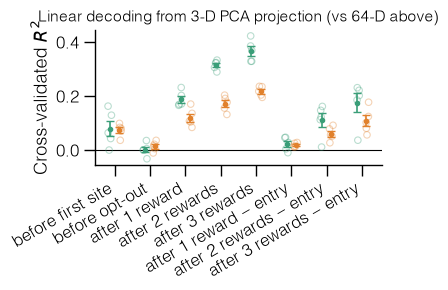

In [ ]:
# Same linear decoding but from the 3-D PCA projection instead of the full 64-D hidden state.
decode_results_pca = []
for i in NETS:
    d = net_data[i]
    d_pca = {**d, 'states': d['pcs']}   # swap 64-D states for 3-D PCA projection
    for row in decode_reward_cv(d_pca, patch_types=PATCH_TYPES, alpha=0, undersample=False):
        decode_results_pca.append(dict(net=i, **row))
        r2s = f"{row['cv_r2']:+.3f}" if not np.isnan(row['cv_r2']) else ' n/a '
        print(f"net{i} | type {row['patch_type']} | {row['condition']:<17} | CV R^2 = {r2s}")

COND_ORDER_PCA = list(dict.fromkeys(r['condition'] for r in decode_results_pca))
plot_decoder_results(decode_results_pca, COND_ORDER_PCA,
                     'Linear decoding from 3-D PCA projection (vs 64-D above)')


net0: 17 unique fixed points from 100 converged
  type 1 | before first site | CV R^2 = +0.015
  type 2 | before first site | CV R^2 = +0.032
  type 1 | before opt-out    | CV R^2 = +0.007
  type 2 | before opt-out    | CV R^2 = -0.010
  type 1 | after 1 reward    | CV R^2 = +0.036
  type 2 | after 1 reward    | CV R^2 = +0.072
  type 1 | after 2 rewards   | CV R^2 = +0.074
  type 2 | after 2 rewards   | CV R^2 = +0.117
  type 1 | after 3 rewards   | CV R^2 = +0.095
  type 2 | after 3 rewards   | CV R^2 = +0.158
  type 1 | after 1 reward − entry | CV R^2 = -0.014
  type 2 | after 1 reward − entry | CV R^2 = -0.009
  type 1 | after 2 rewards − entry | CV R^2 = -0.005
  type 2 | after 2 rewards − entry | CV R^2 = -0.001
  type 1 | after 3 rewards − entry | CV R^2 = -0.039
  type 2 | after 3 rewards − entry | CV R^2 = +0.019
net1: 17 unique fixed points from 100 converged
  type 1 | before first site | CV R^2 = -0.005
  type 2 | before first site | CV R^2 = +0.075
  type 1 | before opt-ou

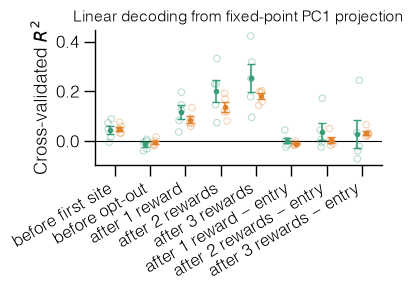

In [ ]:
# Linear decoding from the first PC of the fixed points found under input [1,0,0,0,0,1,0].
# Requires fpwi-consts + fpwi-trainstate cells to have been run (for train_state / constants).
X_FP_INPUT = jnp.array([1., 0., 0., 0., 0., 1., 0.])
N_FP_INITS = 100
FP_UNIQUENESS_THR = 0.1

decode_results_fp_pc = []
for i in NETS:
    final_ckpt = net_checkpoints(i)[-1]
    params_i = checkpoints.restore_checkpoint(
        ckpt_dir=Path(final_ckpt).resolve(), target=train_state).params
    network_fp = A2CRNNFlax(action_size=ACTION_SIZE, obs_size=OBS_SIZE,
                            hidden_size=HIDDEN_SIZE, rnn_type=RNN_TYPE, unit_noise_std=0.0)

    d = net_data[i]
    rng = np.random.default_rng(i)
    h_inits = jnp.asarray(
        d['states'][rng.choice(d['states'].shape[0], size=N_FP_INITS, replace=False)])

    fp_all, conv, _ = find_fixed_points_batch(
        params_i, network_fp, X_FP_INPUT, h_inits, max_steps=2000, tolerance=1e-3)
    fps = np.asarray(
        filter_unique_fixed_points(fp_all, conv, FP_UNIQUENESS_THR)).reshape(-1, HIDDEN_SIZE)
    print(f'net{i}: {fps.shape[0]} unique fixed points from {conv.sum()} converged')
    if fps.shape[0] < 2:
        print(f'  -> too few fixed points, skipping net{i}')
        continue

    fp_pca = PCA(n_components=1).fit(fps)
    proj = fp_pca.transform(d['states'])   # (N, 1)

    d_fp = {**d, 'states': proj}
    for row in decode_reward_cv(d_fp, patch_types=PATCH_TYPES, alpha=0, undersample=False):
        decode_results_fp_pc.append(dict(net=i, n_fps=fps.shape[0], **row))
        r2s = f"{row['cv_r2']:+.3f}" if not np.isnan(row['cv_r2']) else ' n/a '
        print(f"  type {row['patch_type']} | {row['condition']:<17} | CV R^2 = {r2s}")

COND_ORDER_FP = list(dict.fromkeys(r['condition'] for r in decode_results_fp_pc))
plot_decoder_results(decode_results_fp_pc, COND_ORDER_FP,
                     'Linear decoding from fixed-point PC1 projection')


In [ ]:
# # Ridge vs KernelRidge(rbf) comparison — same CV setup, alpha=1 for both.
# DECODE_KWARGS = dict(patch_types=PATCH_TYPES, alpha=1.0, undersample=False)
# MODELS = [('Ridge (linear)', None), ('KernelRidge (rbf)', 'rbf')]

# results_by_model = {label: [] for label, _ in MODELS}
# for i in NETS:
#     d = net_data[i]
#     for label, kernel in MODELS:
#         for row in decode_reward_cv(d, kernel=kernel, **DECODE_KWARGS):
#             results_by_model[label].append(dict(net=i, **row))

# COND_ORDER_KR = list(dict.fromkeys(r['condition'] for r in results_by_model['Ridge (linear)']))
# x = np.arange(len(COND_ORDER_KR))
# width = 0.35
# colors = {'Ridge (linear)': 'C0', 'KernelRidge (rbf)': 'C1'}
# jit = np.random.default_rng(0)

# fig, axes = plt.subplots(1, len(PATCH_TYPES), figsize=(4.5 * len(PATCH_TYPES) + 1, 3.8), sharey=True)
# axes = np.atleast_1d(axes)
# for ax, t in zip(axes, PATCH_TYPES):
#     for mi, (label, rows) in enumerate(results_by_model.items()):
#         offsets = (mi - 0.5) * width
#         for xi, cond in enumerate(COND_ORDER_KR):
#             vals = [r['cv_r2'] for r in rows
#                     if r['patch_type'] == t and r['condition'] == cond and not np.isnan(r['cv_r2'])]
#             if vals:
#                 xpos = xi + offsets
#                 ax.bar(xpos, np.mean(vals), width=width * 0.9, color=colors[label],
#                        alpha=0.8, zorder=1, label=label if xi == 0 else None)
#                 ax.scatter(xpos + jit.uniform(-0.05, 0.05, len(vals)), vals,
#                            color=colors[label], s=18, edgecolor='k', linewidth=0.4, zorder=3)
#     ax.axhline(0, color='k', lw=0.8, zorder=2)
#     ax.set_xticks(x)
#     ax.set_xticklabels(COND_ORDER_KR, rotation=25, ha='right', fontsize=7)
#     ax.set_title(f'Patch type {t}', fontsize=12)
#     format_plot(ax)
# axes[0].set_ylabel('Cross-validated $R^2$', fontsize=9)
# axes[0].legend(fontsize=8, frameon=False)
# fig.suptitle('Ridge vs KernelRidge(rbf) decoding of session mean rewards', fontsize=12)
# fig.tight_layout()
# plt.show()

# print('\nDelta R^2 (KernelRidge - Ridge), mean across nets:')
# for t in PATCH_TYPES:
#     for cond in COND_ORDER_KR:
#         lin = [r['cv_r2'] for r in results_by_model['Ridge (linear)']
#                if r['patch_type'] == t and r['condition'] == cond and not np.isnan(r['cv_r2'])]
#         krr = [r['cv_r2'] for r in results_by_model['KernelRidge (rbf)']
#                if r['patch_type'] == t and r['condition'] == cond and not np.isnan(r['cv_r2'])]
#         if lin and krr:
#             delta = np.mean(krr) - np.mean(lin)
#             print(f'  type {t} | {cond:<20} | \u0394 = {delta:+.3f}  (linear={np.mean(lin):+.3f}, rbf={np.mean(krr):+.3f})')


In [ ]:
# Distribution of col_pts (session x patch-type mean rewards) across all nets and patch types.
all_col = {t: [] for t in PATCH_TYPES}
all_col_by_net = {(i, t): [] for i in NETS for t in PATCH_TYPES}

for i in NETS:
    d = net_data[i]
    sess, pt, col = d['sess_pts'], d['pt_pts'], d['col_pts']
    for t in PATCH_TYPES:
        m = pt == t
        _, idx = np.unique(sess[m], return_index=True)
        vals = col[m][idx]
        all_col[t].extend(vals.tolist())
        all_col_by_net[(i, t)].extend(vals.tolist())

fig, axes = plt.subplots(1, len(PATCH_TYPES), figsize=(4.5 * len(PATCH_TYPES), 3.5), sharey=False)
axes = np.atleast_1d(axes)
colors = [f'C{i}' for i in NETS]

for ax, t in zip(axes, PATCH_TYPES):
    all_vals = np.array(all_col[t])
    bins = np.linspace(all_vals.min(), all_vals.max(), 25)
    for i in NETS:
        vals = np.array(all_col_by_net[(i, t)])
        ax.hist(vals, bins=bins, alpha=0.5, color=colors[i], label=f'net{i}', density=True)
    ax.set_xlabel('Mean rewards collected per patch in session')
    ax.set_ylabel('Density')
    ax.set_title(f'Patch type {t}  (n={len(all_vals)} sessions total)')
    ax.legend(fontsize=7, frameon=False)
    format_plot(ax)

fig.suptitle('Distribution of col_pts (target for decoders)', fontsize=12)
fig.tight_layout()
plt.show()

for t in PATCH_TYPES:
    v = np.array(all_col[t])
    print(f'Patch type {t}: min={v.min():.2f}  median={np.median(v):.2f}  max={v.max():.2f}'
          f'  mean={v.mean():.2f}  std={v.std():.2f}  n={len(v)}'
          f'  skew={float(((v - v.mean())**3).mean() / v.std()**3):.2f}')


## Fixed points along the checkpoint-weight interpolation

`plot_fixedpoint_weight_interpolation_3d` (and the constants / `train_state` template it needs) are
copied verbatim from `gru_networks_offset_exp_decay_dynamics_demo_evo.ipynb`. For each
interpatch-shorten curriculum net, it walks the piecewise-linear path through that net's training
checkpoints (`step_00` -> `step_01`, in order) and, for a single fixed input, tracks how the
actor-GRU fixed points move / change stability. **Expensive** (one fixed-point search per
interpolation step, per net) — lower `n_interp` / `n_inits` to speed it up.

In [ ]:
# Some config variables so that network weights can actually be loaded
HIDDEN_SIZE = 64
ACTION_SIZE = 2
OBS_SIZE = 4
RNN_TYPE = "GRU"
UNIT_NOISE_STD = 1e-2
LEARNING_RATE = 0
SEED = 0
NUM_ENVS = 1

# Configuration
CONFIG = {
    'hidden_size': 64,
    'action_size': 2,
    'obs_size': 4,
    'rnn_type': 'GRU',  # or 'VANILLA'
    'unit_noise_std': 0.0,
}

# Define input context
# Input format: [obs(4), prev_action_onehot(2), prev_reward(1)]
input_dim = CONFIG['obs_size'] + CONFIG['action_size'] + 1

In [ ]:
# --- INITIALIZE NETWORK + TRAIN STATE ---
rng_key = jax.random.key(SEED)
net_init_key, rng_key = jax.random.split(rng_key)

network, params = init_network_and_params(
    hidden_size=HIDDEN_SIZE,
    action_size=ACTION_SIZE,
    obs_size=OBS_SIZE,
    rnn_type=RNN_TYPE,
    unit_noise_std=UNIT_NOISE_STD,
    rng_key=net_init_key,
)

train_state = create_train_state(
    rng_key=rng_key,
    obs_size=OBS_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_envs=NUM_ENVS,
    learning_rate=LEARNING_RATE,
    params=params,
)

In [ ]:
# --- Fixed points along a CHECKPOINT-WEIGHT interpolation, in a 3-D (PC1, PC2, index) plot ---
# Like plot_fixedpoint_interpolation_3d, but the interpolation is across network WEIGHTS
# rather than the input. For a single fixed input x_input, walk the piecewise-linear path
# through the checkpoints' actor weights (same checkpoint list you pass to
# compare_actor_weights_across_checkpoints): parameter t in [0, n_ckpt - 1] is sampled
# n_interp times, and at each t the params of the two bracketing checkpoints are linearly
# blended. At each blend, find the actor-GRU fixed points under x_input. A single 2-D PCA is
# fit over pooled trajectory activity across the checkpoints; then FOUR scatters are drawn over
# the same points/space: two 3-D (axes = the two activity PCs, third axis = interpolation
# index) and two 2-D (axes = the two PCs, index folded into colour), each coloured either by
# checkpoint index t or by each fixed point's max |eigenvalue|.
# NOTE: cost scales with n_interp (one fixed-point search per point) and with the number of
# checkpoints restored; raise n_interp for a denser path, lower it to go faster.

from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers 3d projection)

def plot_fixedpoint_weight_interpolation_3d(all_ckpts, all_trajs, x_input, n_interp=41, n_inits=100,
                                            max_steps=2000, tolerance=1e-3, uniqueness_threshold=0.1,
                                            max_pca_files=8, pca_points_per_file=2000,
                                            figsize=(6, 6), cmap='viridis', eig_cmap='magma',
                                            change_index=None, save_dir=None,
                                            save_stem='fp_interp'):
    x = jnp.asarray(np.asarray(x_input, float))
    network_fp = A2CRNNFlax(action_size=ACTION_SIZE, obs_size=OBS_SIZE, hidden_size=HIDDEN_SIZE,
                            rnn_type=RNN_TYPE, unit_noise_std=0.0)
    params_list = [checkpoints.restore_checkpoint(ckpt_dir=Path(cp).resolve(), target=train_state).params
                   for cp in all_ckpts]
    n_ck = len(params_list)

    # PCA basis + FP-search inits from pooled activity across the checkpoints' trajectories.
    rng = np.random.default_rng(0)
    files = all_trajs
    if max_pca_files is not None and len(all_trajs) > max_pca_files:
        keep = np.unique(np.linspace(0, len(all_trajs) - 1, max_pca_files).round().astype(int))
        files = [all_trajs[i] for i in keep]
    pooled = []
    for f in files:
        ah = np.asarray(parse_behavioral_data(load_trajectory_data(f)[0])['actor_hidden'])
        k = min(pca_points_per_file, ah.shape[0])
        pooled.append(ah[rng.choice(ah.shape[0], size=k, replace=False)])
    pooled = np.concatenate(pooled, axis=0)
    pca = PCA(n_components=2).fit(pooled)
    h_inits = jnp.asarray(pooled[rng.choice(pooled.shape[0], size=n_inits, replace=False)])

    # Fixed points under the single input x, as the weights interpolate along the checkpoint path.
    ts = np.linspace(0.0, n_ck - 1, n_interp)
    fps_per_t, maxeig_per_t = [], []
    for t in ts:
        i = int(np.floor(t)); a = t - i
        if i >= n_ck - 1:
            p = params_list[-1]
        else:
            p = jax.tree_util.tree_map(lambda u, v: (1 - a) * u + a * v, params_list[i], params_list[i + 1])
        fp_all, conv, _ = find_fixed_points_batch(p, network_fp, x, h_inits,
                                                  max_steps=max_steps, tolerance=tolerance)
        fps = np.asarray(filter_unique_fixed_points(fp_all, conv, uniqueness_threshold)).reshape(-1, HIDDEN_SIZE)
        fps_per_t.append(fps)
        if fps.shape[0]:
            eigs = np.asarray(analyze_stability_batch(jnp.asarray(fps), x, p, network_fp))
            maxeig_per_t.append(np.abs(eigs).max(axis=1))
        else:
            maxeig_per_t.append(np.zeros(0))

    alleig = np.concatenate([m for m in maxeig_per_t if m.size])
    evmin, evmax = float(alleig.min()), float(alleig.max())

    # Offset the index axis so 0 sits at the curriculum change rather than at training start.
    off = 0 if change_index is None else float(change_index)

    def _draw(color_by_eig, three_d):
        fig = plt.figure(figsize=figsize)
        ax = fig.add_subplot(111, projection='3d') if three_d else fig.add_subplot(111)
        col_cmap = eig_cmap if color_by_eig else cmap
        vmn, vmx = (evmin, evmax) if color_by_eig else (0 - off, n_ck - 1 - off)
        for t, fps, me in zip(ts, fps_per_t, maxeig_per_t):
            if not fps.shape[0]:
                continue
            p2 = pca.transform(fps)
            cvals = me if color_by_eig else np.full(p2.shape[0], t - off)
            if three_d:
                ax.scatter(p2[:, 0], p2[:, 1], np.full(p2.shape[0], t - off), c=cvals, cmap=col_cmap,
                           vmin=vmn, vmax=vmx, s=15, depthshade=False)
            else:
                ax.scatter(p2[:, 0], p2[:, 1], c=cvals, cmap=col_cmap, vmin=vmn, vmax=vmx, s=15)
        # equal PC1/PC2 spans so the x/y footprint stays SQUARE (pad the shorter axis with white space)
        x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
        half = 0.5 * (max(x1 - x0, y1 - y0) or 1)
        cx, cy = 0.5 * (x0 + x1), 0.5 * (y0 + y1)
        ax.set_xlim(cx - half, cx + half); ax.set_ylim(cy - half, cy + half)
        if three_d:
            ax.set_aspect('equalxy')                     # equal PC1/PC2 scale; index axis left free
        else:
            ax.set_aspect('equal', adjustable='box')     # equal PC1/PC2 scale -> square footprint
        ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
        if three_d:
            ax.set_zlabel('checkpoint interp. (index)' if change_index is None
                          else 'checkpoints from curriculum change')
        dim = '3D' if three_d else '2D'
        collab = 'max |eig|' if color_by_eig else 'index'
        ax.set_title(f'Fixed points along checkpoint-weight interpolation ({dim}, colour = {collab})',
                     fontsize=9)
        cbar_lab = ('max |eigenvalue|' if color_by_eig else
                    ('checkpoint index' if change_index is None
                     else 'checkpoints from curriculum change'))
        sm = plt.cm.ScalarMappable(cmap=col_cmap, norm=plt.Normalize(vmn, vmx)); sm.set_array([])
        fig.colorbar(sm, ax=ax, label=cbar_lab, shrink=0.5,
                     pad=0.1 if three_d else 0.02)
        if not three_d:
            format_plot(ax)   # spine/tick styling; a 3D axis has no spines to format
        fig.tight_layout()
        if save_dir is not None:
            os.makedirs(save_dir, exist_ok=True)
            _tag = f"{'3d' if three_d else '2d'}_{'eig' if color_by_eig else 'index'}"
            _out = os.path.join(save_dir, f'{save_stem}_{_tag}.svg')
            fig.savefig(_out, format='svg', bbox_inches='tight')
            print(f'  saved {_out}')
        plt.show()

    _draw(color_by_eig=False, three_d=True)    # 3D, coloured by checkpoint-interpolation index
    _draw(color_by_eig=True,  three_d=True)    # 3D, coloured by max |eigenvalue|
    _draw(color_by_eig=False, three_d=False)   # 2D (PC1 vs PC2), coloured by checkpoint index
    _draw(color_by_eig=True,  three_d=False)   # 2D (PC1 vs PC2), coloured by max |eigenvalue|
    return ts, fps_per_t, maxeig_per_t, pca

=== full_net0: 30 checkpoints -> fixed-point weight interpolation ===


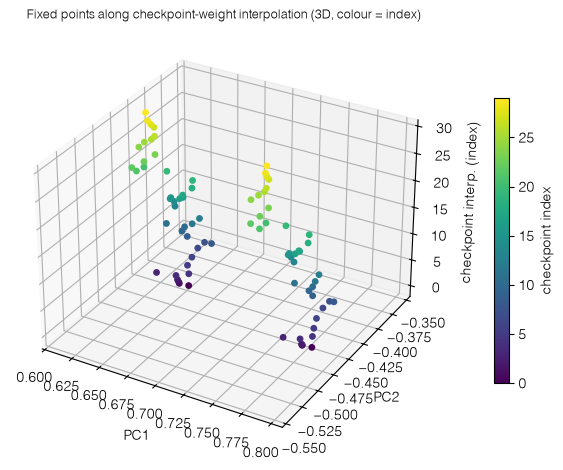

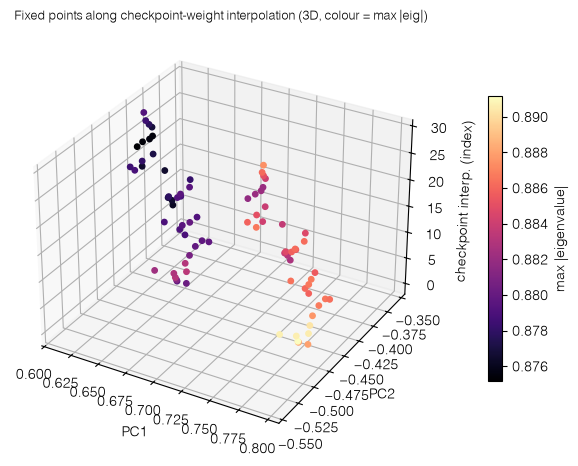

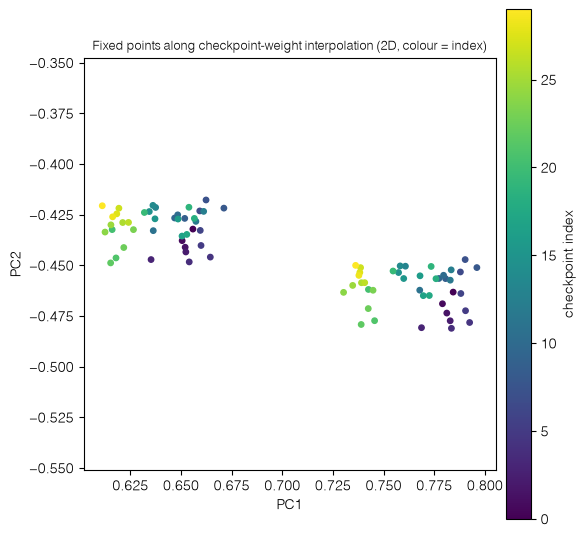

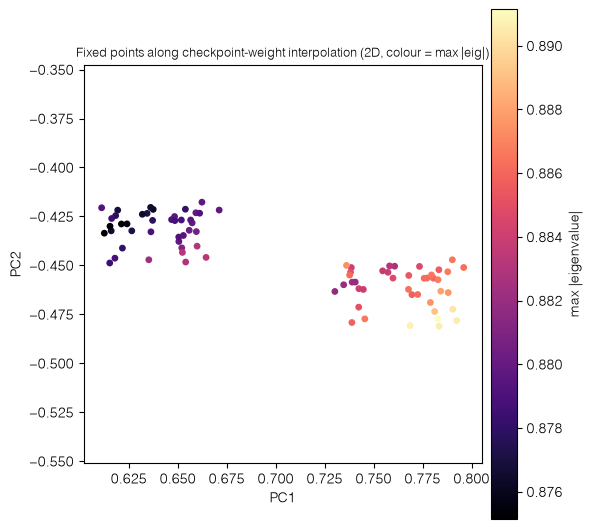

=== full_net1: 30 checkpoints -> fixed-point weight interpolation ===


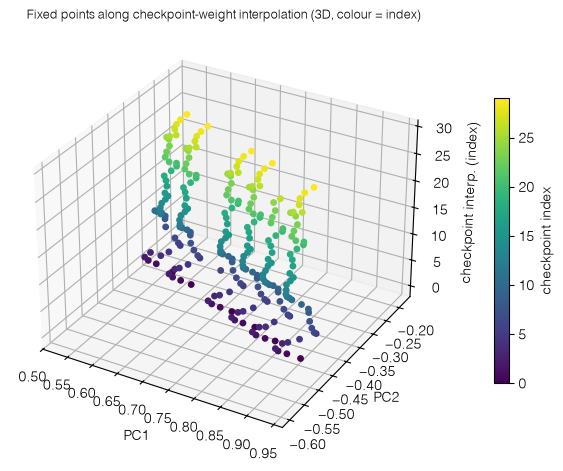

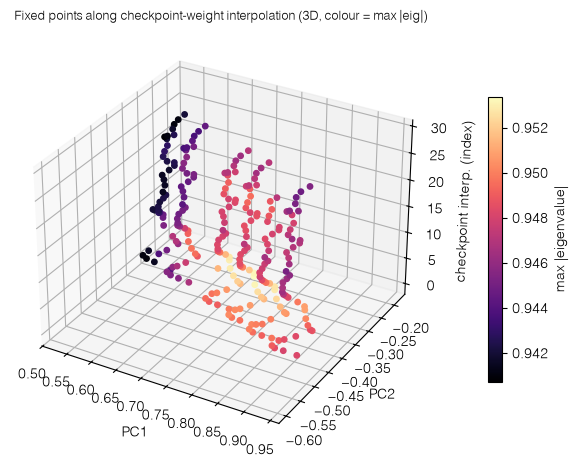

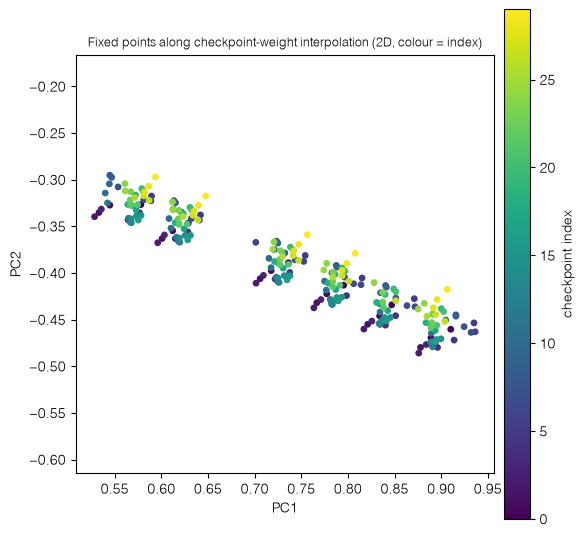

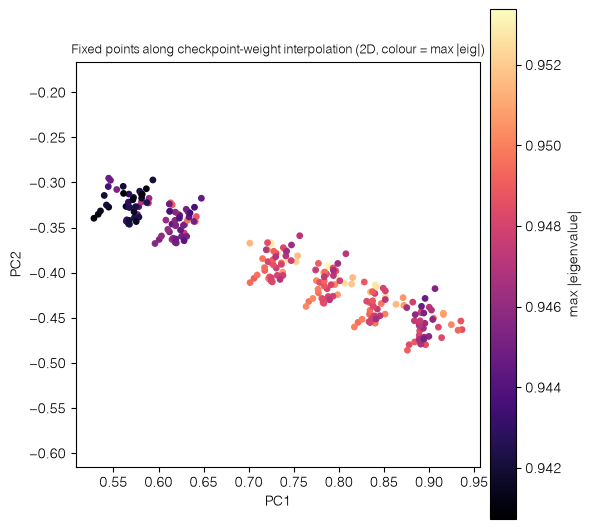

=== full_net2: 30 checkpoints -> fixed-point weight interpolation ===


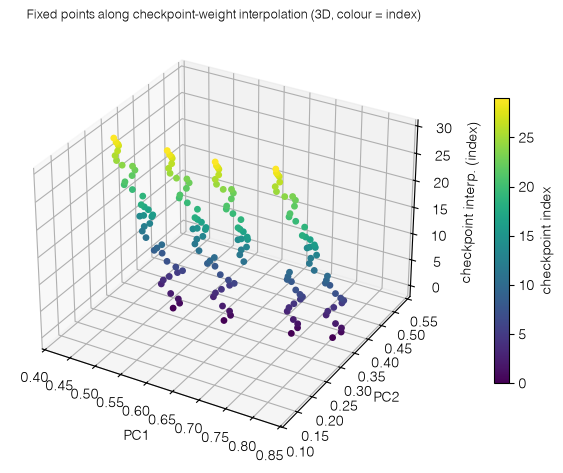

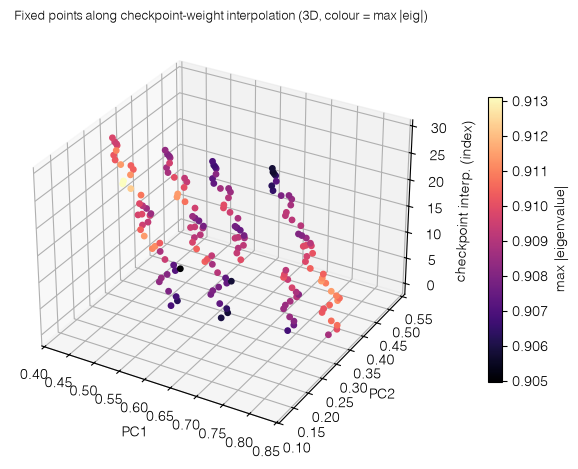

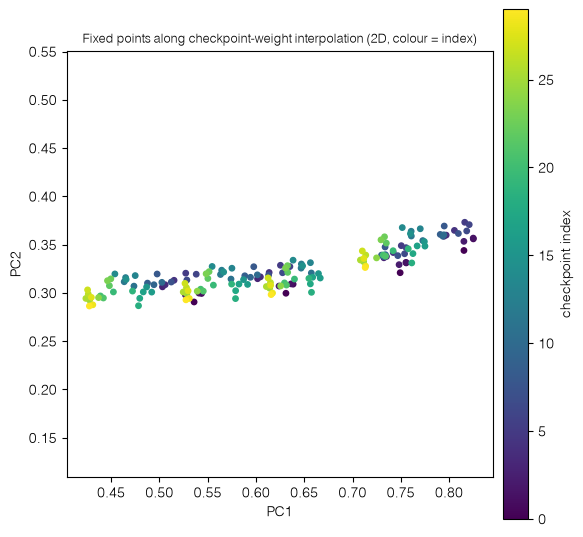

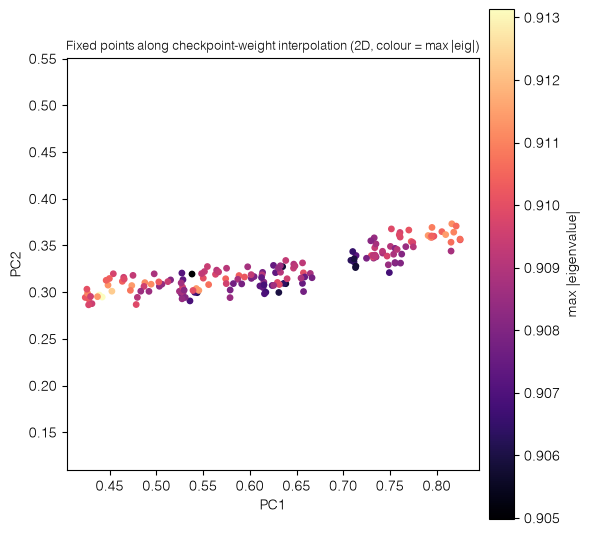

=== full_net3: 30 checkpoints -> fixed-point weight interpolation ===


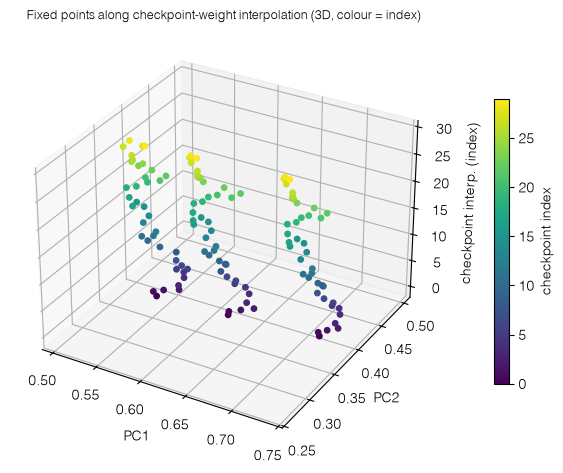

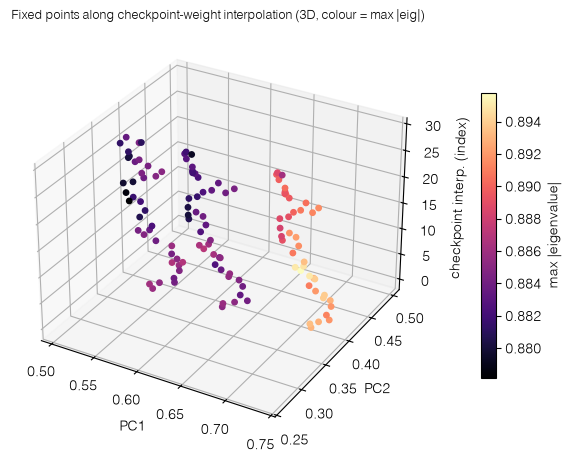

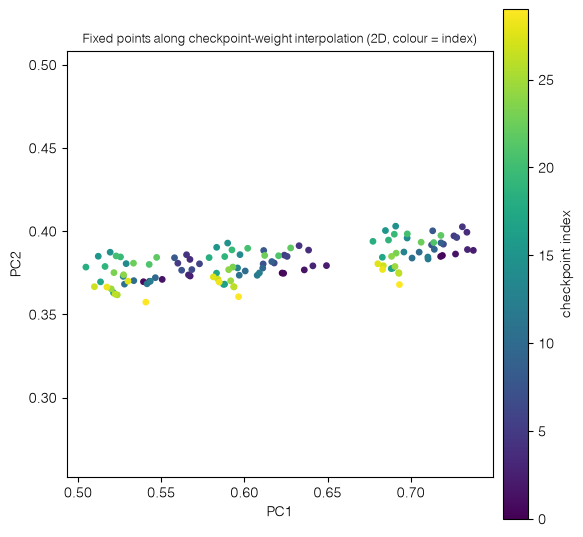

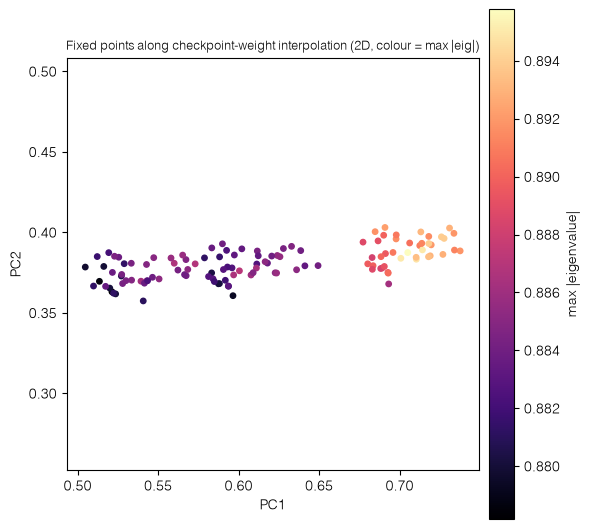

=== full_net4: 30 checkpoints -> fixed-point weight interpolation ===


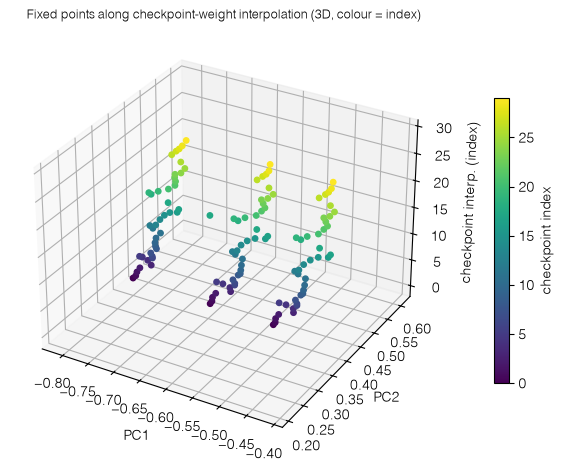

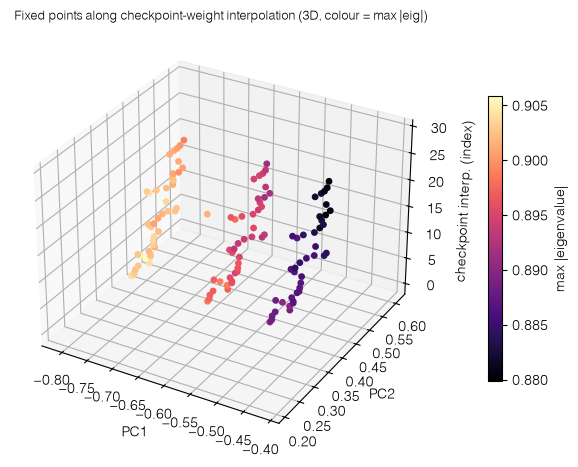

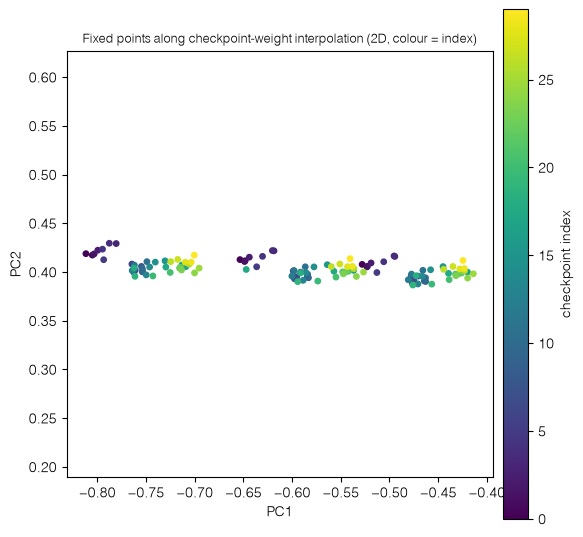

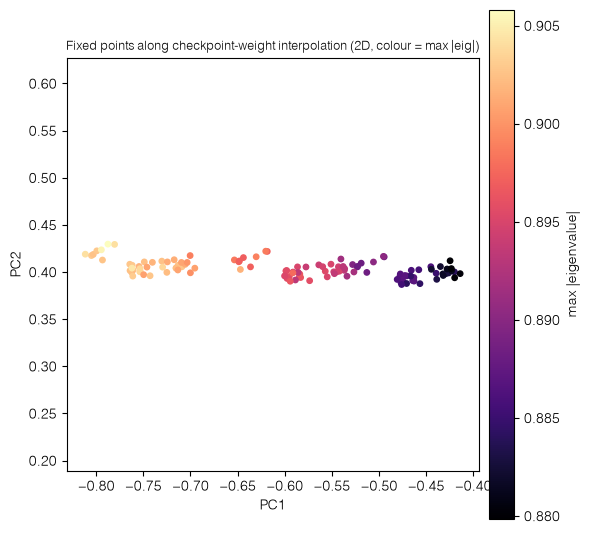

In [ ]:
# Checkpoints for each net, ordered by curriculum step then checkpoint index (step_00: 0..9 -> step_01: 0..19).
def net_checkpoints(i):
    base = f'../../../checkpoints/fixed_exp_gru_initial_prob_offset_interpatch_shorten_full_net{i}'
    paths = glob.glob(f'{base}/step_*/checkpoint_*')
    return sorted(paths, key=lambda q: (int(re.search(r'step_(\d+)', q).group(1)),
                                        int(re.search(r'checkpoint_(\d+)$', q).group(1))))

# Single fixed input [obs(4), prev_action_onehot(2), prev_reward(1)]: in-patch, no odor site, prev 'go', no reward.
X_INPUT = [0, 0, 0, 0, 0, 1, 0]

for i in NETS:
    ckpts = net_checkpoints(i)
    print(f'=== full_net{i}: {len(ckpts)} checkpoints -> fixed-point weight interpolation ===')
    _ = plot_fixedpoint_weight_interpolation_3d(
        ckpts, net_trajectories(i), x_input=X_INPUT,
        # 0 on the index axis = the curriculum change (end of step_00)
        change_index=sum(1 for c in ckpts if 'step_00' in c),
        # n_interp=21, n_inits=60,   # <- uncomment to run faster
    )

=== full_net0: 30 checkpoints -> fixed-point weight interpolation ===


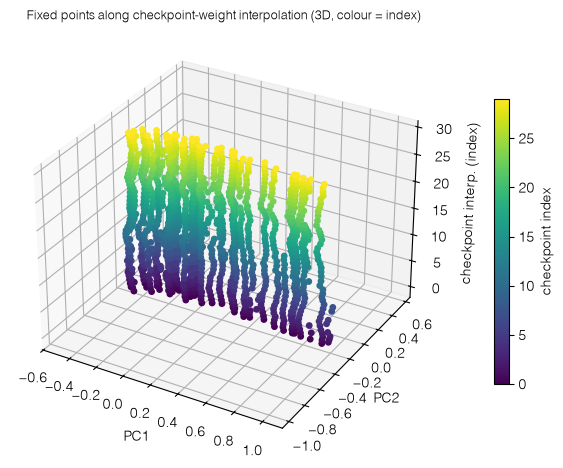

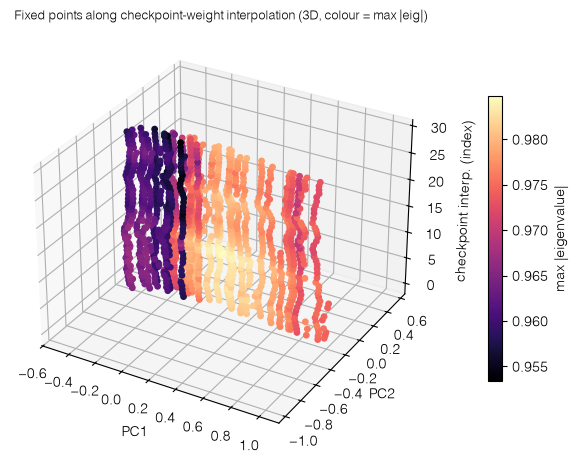

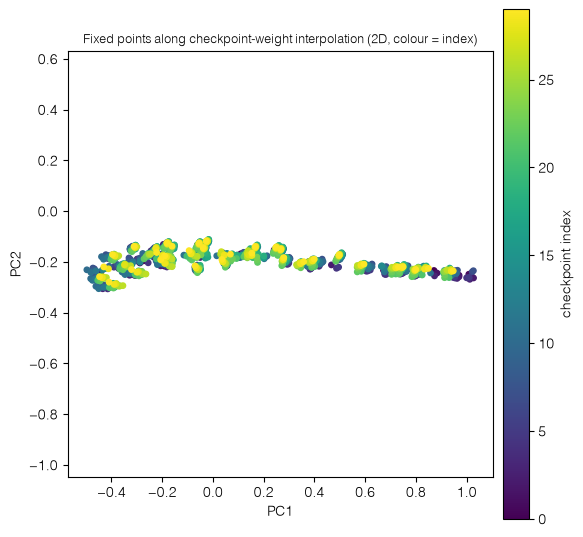

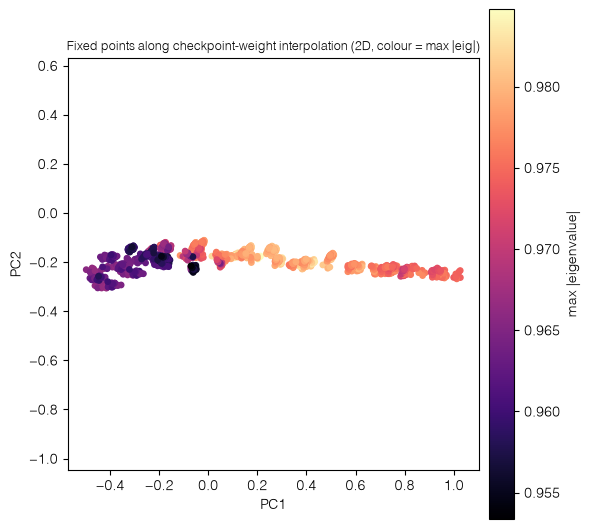

=== full_net1: 30 checkpoints -> fixed-point weight interpolation ===


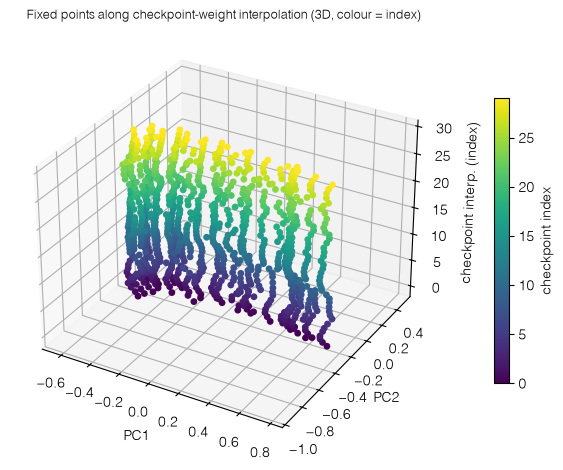

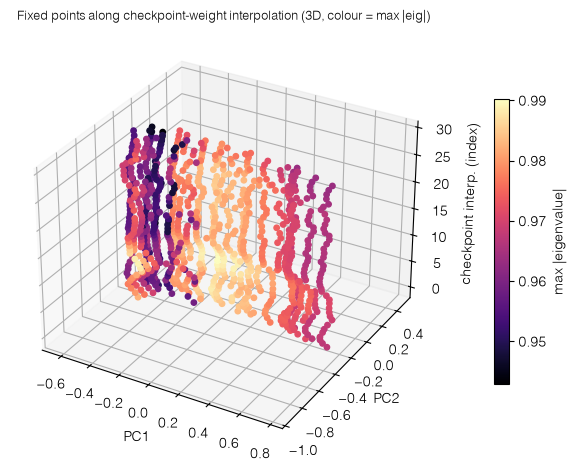

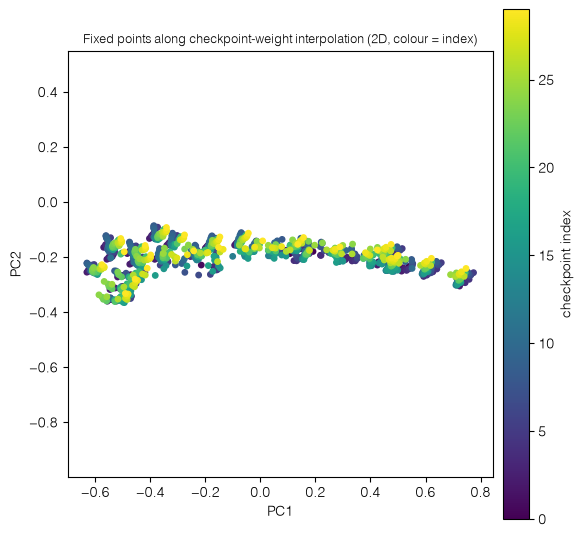

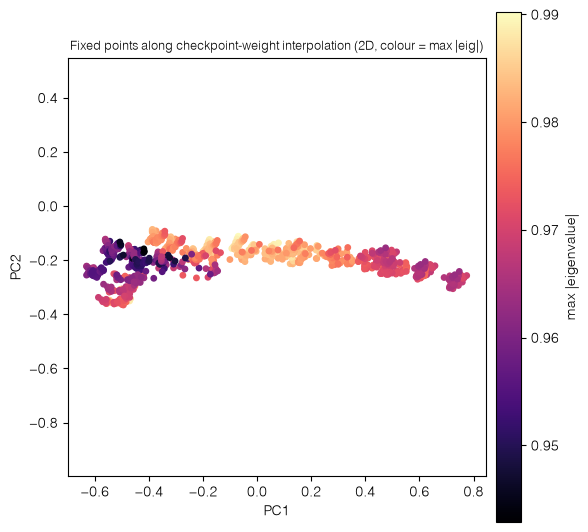

=== full_net2: 30 checkpoints -> fixed-point weight interpolation ===


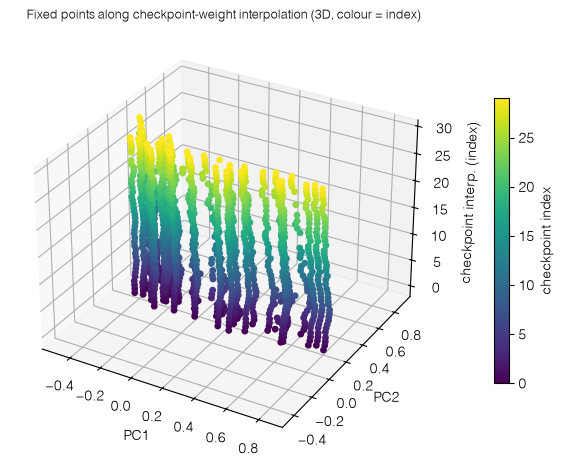

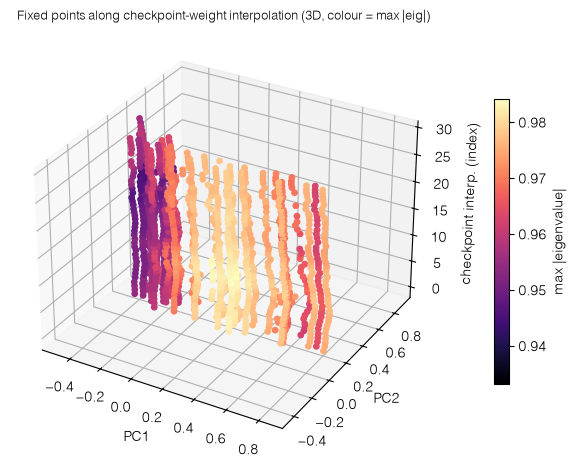

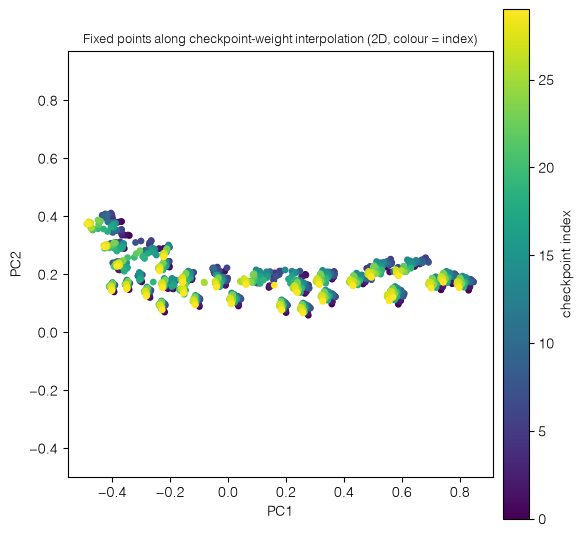

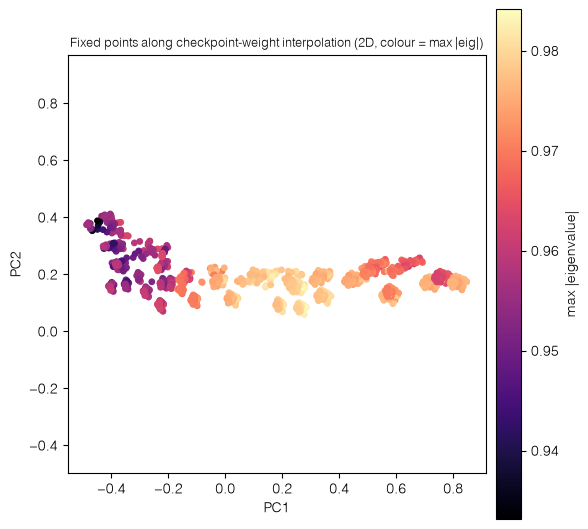

=== full_net3: 30 checkpoints -> fixed-point weight interpolation ===


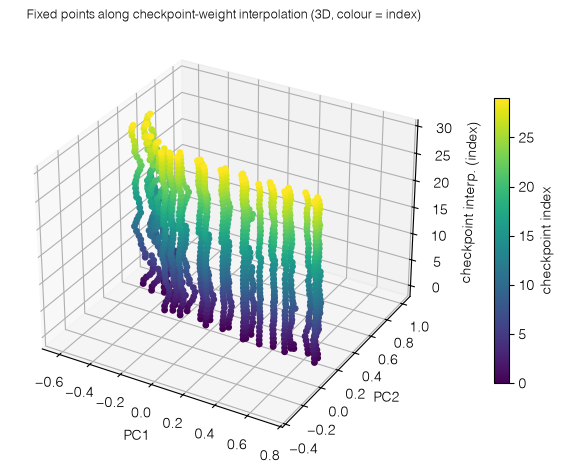

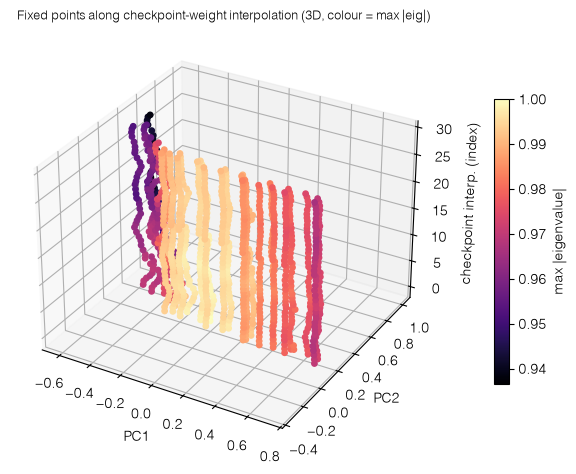

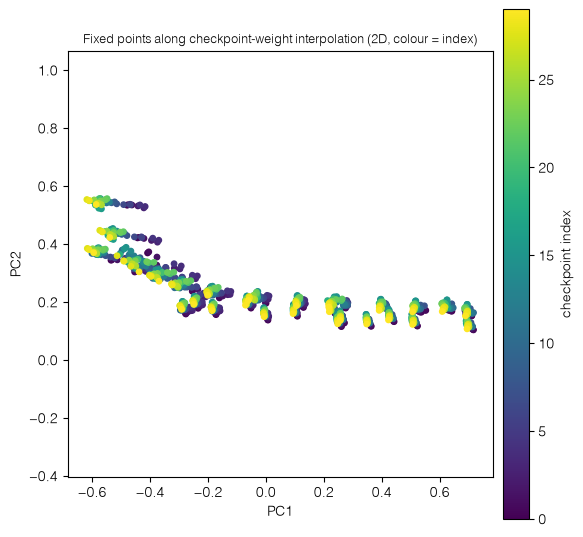

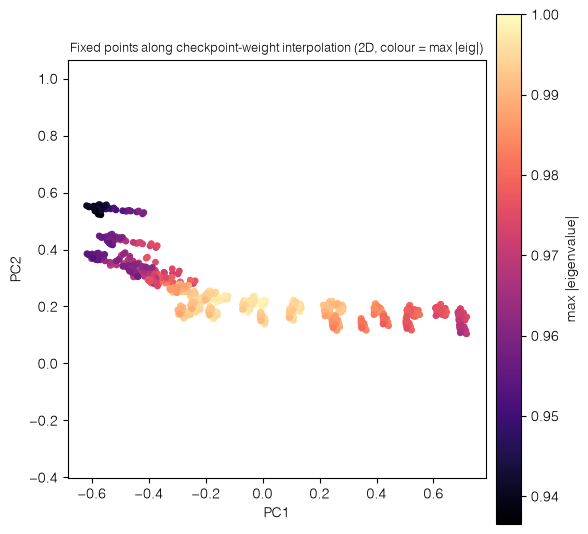

=== full_net4: 30 checkpoints -> fixed-point weight interpolation ===


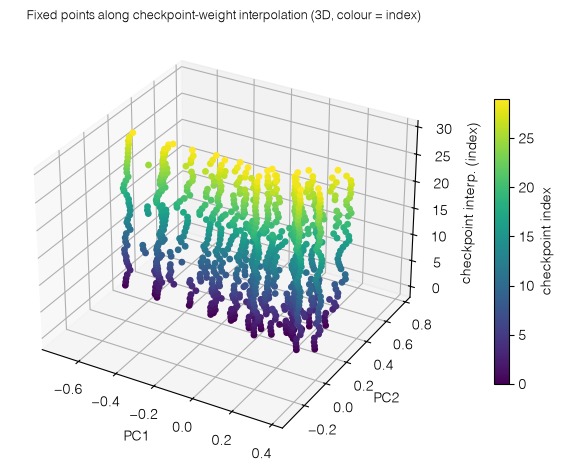

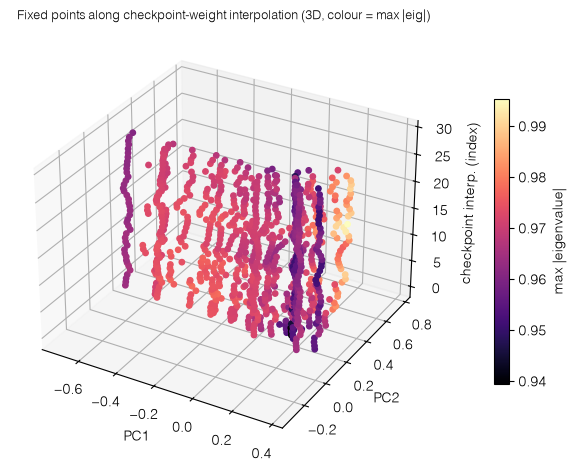

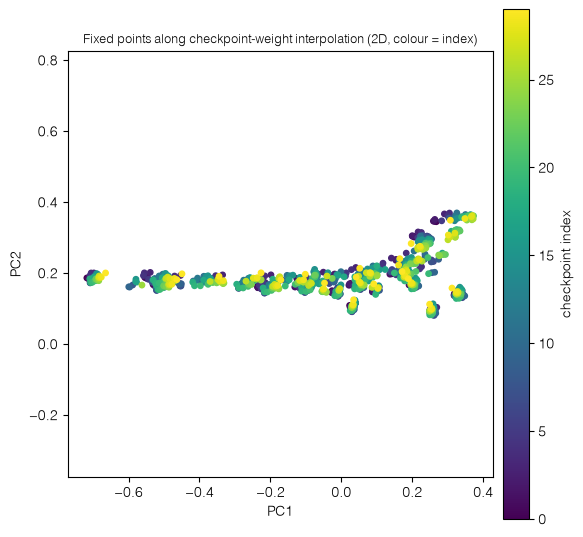

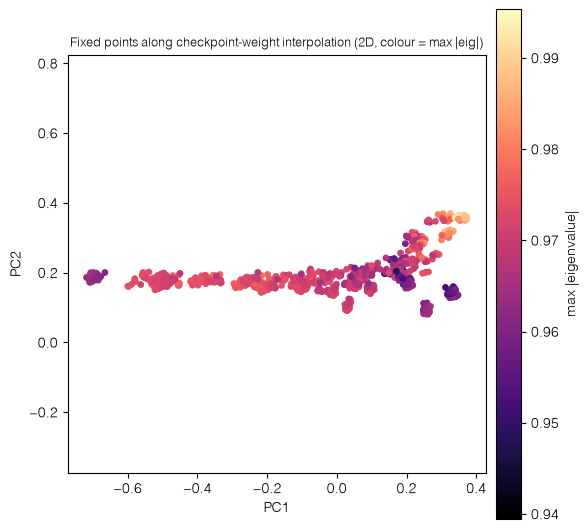

In [ ]:
# SVGs for this input only; other X_INPUT cells are left unsaved.
FP_INTERP_FIG_DIR = f'{FIG_ROOT}/fp_weight_interp_in_patch_no_odor'

# Single fixed input [obs(4), prev_action_onehot(2), prev_reward(1)]: in-patch, no odor site, prev 'go', no reward.
X_INPUT = [1, 0, 0, 0, 0, 1, 0]

for i in NETS:
    ckpts = net_checkpoints(i)
    print(f'=== full_net{i}: {len(ckpts)} checkpoints -> fixed-point weight interpolation ===')
    _ = plot_fixedpoint_weight_interpolation_3d(
        ckpts, net_trajectories(i), x_input=X_INPUT,
        # 0 on the index axis = the curriculum change (end of step_00)
        change_index=sum(1 for c in ckpts if 'step_00' in c),
        save_dir=f'{FP_INTERP_FIG_DIR}/net{i}',
        # n_interp=21, n_inits=60,   # <- uncomment to run faster
    )


In [ ]:
# Single fixed input [obs(4), prev_action_onehot(2), prev_reward(1)]: in-patch, no odor site, prev 'go', no reward.
X_INPUT = [1, 0, 1, 0, 0, 1, 0]

for i in NETS:
    ckpts = net_checkpoints(i)
    print(f'=== full_net{i}: {len(ckpts)} checkpoints -> fixed-point weight interpolation ===')
    _ = plot_fixedpoint_weight_interpolation_3d(
        ckpts, net_trajectories(i), x_input=X_INPUT,
        # 0 on the index axis = the curriculum change (end of step_00)
        change_index=sum(1 for c in ckpts if 'step_00' in c),
        # n_interp=21, n_inits=60,   # <- uncomment to run faster
    )

# Single fixed input [obs(4), prev_action_onehot(2), prev_reward(1)]: in-patch, no odor site, prev 'go', no reward.
X_INPUT = [1, 0, 1, 0, 1, 0, 0]

for i in NETS:
    ckpts = net_checkpoints(i)
    print(f'=== full_net{i}: {len(ckpts)} checkpoints -> fixed-point weight interpolation ===')
    _ = plot_fixedpoint_weight_interpolation_3d(
        ckpts, net_trajectories(i), x_input=X_INPUT,
        # 0 on the index axis = the curriculum change (end of step_00)
        change_index=sum(1 for c in ckpts if 'step_00' in c),
        # n_interp=21, n_inits=60,   # <- uncomment to run faster
    )

In [ ]:
# Single fixed input [obs(4), prev_action_onehot(2), prev_reward(1)]: in-patch, no odor site, prev 'go', no reward.
X_INPUT = [1, 0, 0, 1, 0, 1, 0]

for i in NETS:
    ckpts = net_checkpoints(i)
    print(f'=== full_net{i}: {len(ckpts)} checkpoints -> fixed-point weight interpolation ===')
    _ = plot_fixedpoint_weight_interpolation_3d(
        ckpts, net_trajectories(i), x_input=X_INPUT,
        # 0 on the index axis = the curriculum change (end of step_00)
        change_index=sum(1 for c in ckpts if 'step_00' in c),
        # n_interp=21, n_inits=60,   # <- uncomment to run faster
    )

# Single fixed input [obs(4), prev_action_onehot(2), prev_reward(1)]: in-patch, no odor site, prev 'go', no reward.
X_INPUT = [1, 0, 0, 1, 1, 0, 0]

for i in NETS:
    ckpts = net_checkpoints(i)
    print(f'=== full_net{i}: {len(ckpts)} checkpoints -> fixed-point weight interpolation ===')
    _ = plot_fixedpoint_weight_interpolation_3d(
        ckpts, net_trajectories(i), x_input=X_INPUT,
        # 0 on the index axis = the curriculum change (end of step_00)
        change_index=sum(1 for c in ckpts if 'step_00' in c),
        # n_interp=21, n_inits=60,   # <- uncomment to run faster
    )

## Activity PCs vs session mean rewards \u2014 entry / exit / opt-out

For each canonical state kind \u2014 **patch entry** (before first site), **exit** (after N rewards,
right before the next site), and **opt-out** (last inter-site state before leaving) \u2014 scatter the
first two activity PCs (`pcs[:, 0]`, `pcs[:, 1]`) against the session's mean rewards collected
(`col_pts`). One row per patch type; Pearson r annotated. For `kind='exit'`, `N=None` pools all
reward thresholds, or set `N=k`.

In [ ]:
_KIND_LABEL = {'entry': 'patch entry (before first site)',
               'exit': 'exit (after N rewards)', 'optout': 'opt-out'}

def plot_pcs_vs_session_reward(data, kind='exit', N=None, diff_N=None, patch_types=(1, 2),
                               max_points=4000, s=5):
    """Scatter the first 2 activity PCs against the session's mean rewards collected (col_pts).
    Single-state mode: `kind` in {'entry','exit','optout'} (N restricts 'exit' to exactly N rewards).
    Displacement mode: pass `diff_N=k` -> plot the (exit@k - entry) PC displacement, paired within
    each patch instance (PCA is linear, so this is pcs[exit] - pcs[entry])."""
    pcs, col, kp, npt, pt, inst = (data['pcs'], data['col_pts'], data['kind_pts'],
                                   data['n_pts'], data['pt_pts'], data['inst_pts'])
    rng = np.random.default_rng(0)

    def _reward_and_pcs(t):
        if diff_N is not None:                       # (exit@diff_N - entry) displacement, paired per patch
            e_by = {int(inst[j]): j for j in np.where((kp == 'entry') & (pt == t))[0]}
            pairs = [(e_by[int(inst[j])], j)
                     for j in np.where((kp == 'exit') & (npt == diff_N) & (pt == t))[0]
                     if int(inst[j]) in e_by]
            if not pairs:
                return None, None
            er = np.array([a for a, _ in pairs]); xr = np.array([b for _, b in pairs])
            return col[xr], pcs[xr] - pcs[er]
        base = (kp == kind)
        if kind == 'exit' and N is not None:
            base = base & (npt == N)
        m = np.where(base & (pt == t))[0]
        if not m.size:
            return None, None
        return col[m], pcs[m]

    fig, axes = plt.subplots(len(patch_types), 2, figsize=(8, 3.2 * len(patch_types)), squeeze=False)
    for r, t in enumerate(patch_types):
        reward, P = _reward_and_pcs(t)
        if reward is None:
            continue
        idx = np.arange(reward.shape[0])
        if idx.size > max_points:
            idx = rng.choice(idx, size=max_points, replace=False)
        for c in (0, 1):
            ax = axes[r, c]
            x, y = reward[idx], P[idx, c]
            ax.scatter(x, y, s=s, alpha=0.35, color=f'C{r}', edgecolor='none')
            rr = np.corrcoef(x, y)[0, 1] if (x.size > 2 and np.ptp(x) > 0) else np.nan
            ax.set_title(f'type {t} \u2014 PC{c + 1}  (r = {rr:+.2f}, n = {idx.size})', fontsize=10)
            ax.set_xlabel('Mean rewards collected per patch in session')
            ylab = f'PC{c + 1} (exit - entry)' if diff_N is not None else f'PC{c + 1} of activity'
            ax.set_ylabel(ylab)
            format_plot(ax)
    if diff_N is not None:
        ttl = f'(exit@N={diff_N} - entry) PC displacement vs session mean rewards'
    else:
        lbl = _KIND_LABEL.get(kind, kind)
        ttl = f'Activity PCs at {lbl} vs session mean rewards'
        if kind == 'exit':
            ttl += f' (N = {N})' if N is not None else ' (all N)'
    fig.suptitle(ttl, fontsize=11)
    fig.tight_layout()
    plt.show()


In [ ]:
# PC-vs-session-reward plots for patch entry, exit (after N rewards), opt-out, and the
# (exit@diff_N - entry) displacement.
for i in NETS:
    d = load_patch_entry_exit_data(net_trajectories(i))
    for kind in ('entry', 'exit', 'optout'):
        print(f'=== full_net{i} \u2014 {kind} ===')
        plot_pcs_vs_session_reward(d, kind=kind, N=2)
    print(f'=== full_net{i} \u2014 exit - entry (N=2) ===')
    plot_pcs_vs_session_reward(d, diff_N=2)   # set diff_N=k to pair with a different exit threshold


## Distance from the pre-change patch-entry state to the state after N rewards

Anchor: the centroid of the **patch entry** states ("before first site") from
**pre-curriculum-change** sessions only (`step_00`). Every distance on the plot is measured
from that same anchor, so the two curves are directly comparable:

- **solid** — pre-change sessions (`step_00`)
- **dashed** — the last 10 training sessions

For each N the centroid of the states after N rewards in that window is taken and its
Euclidean distance to the anchor is plotted, in the **full 64-D actor hidden space** rather
than the 3-D PCA projection. One panel per patch type, one colour per network. Reads from
`net_data` (run the loading cell above first).


pt1 net0     pre: N=[1, 2, 3, 4, 5, 6] n=[4726, 4709, 4600, 3754, 1500, 197]
pt1 net0  last10: N=[1, 2, 3, 4, 5] n=[5680, 5629, 5098, 2480, 280]
pt1 net1     pre: N=[1, 2, 3, 4, 5, 6] n=[4850, 4830, 4760, 3897, 1223, 81]
pt1 net1  last10: N=[1, 2, 3, 4, 5] n=[5779, 5732, 5138, 2174, 242]
pt1 net2     pre: N=[1, 2, 3, 4, 5, 6] n=[4848, 4816, 4697, 3421, 874, 85]
pt1 net2  last10: N=[1, 2, 3, 4, 5] n=[5913, 5857, 5188, 1843, 111]
pt1 net3     pre: N=[1, 2, 3, 4, 5, 6] n=[4570, 4551, 4535, 4207, 2065, 251]
pt1 net3  last10: N=[1, 2, 3, 4, 5] n=[5651, 5611, 5165, 2641, 244]
pt1 net4     pre: N=[1, 2, 3, 4, 5, 6] n=[4906, 4880, 4817, 4062, 1447, 108]
pt1 net4  last10: N=[1, 2, 3, 4, 5] n=[5704, 5654, 5065, 2055, 125]
pt2 net0     pre: N=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] n=[4642, 4637, 4630, 4621, 4615, 4605, 4588, 4511, 4135, 3236, 1972]
pt2 net0  last10: N=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] n=[5720, 5714, 5700, 5695, 5685, 5661, 5562, 5014, 3601, 1790, 571]
pt2 net1     pre: N=[1, 2, 3,

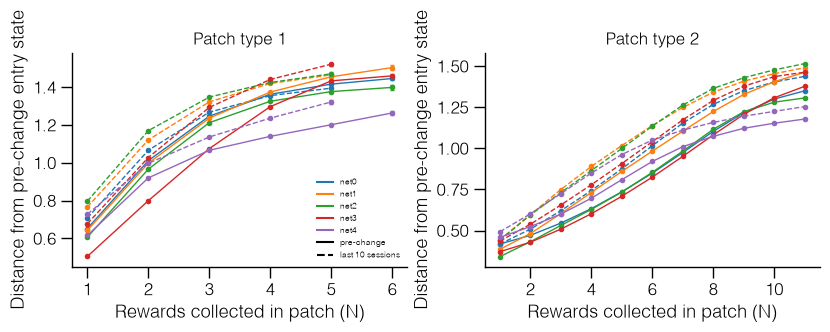

In [39]:
from matplotlib.lines import Line2D

# Distance from the pre-change entry centroid to the post-N-rewards centroid, in full 64-D
# hidden space. The anchor is always pre-change; only the window for the after-N states varies.
MIN_SAMPLES = 20   # skip (patch type, N) cells with too few states to average reliably
LAST_K = 10        # trailing training sessions for the dashed curve


def _sessions_per_file(i, d):
    return (d['sess_pts'].max() + 1) / len(net_trajectories(i))


def pre_change_mask(i, d):
    """States from step_00. load_patch_entry_exit_data numbers sessions consecutively over
    the file list, so the boundary is (step_00 files) x (sessions/file)."""
    n_pre = sum(1 for p in net_trajectories(i) if 'step_00' in p)
    return d['sess_pts'] < int(round(n_pre * _sessions_per_file(i, d)))


def last_k_mask(i, d, k=LAST_K):
    """States from the final k training sessions (= final k trajectory files)."""
    n_files = len(net_trajectories(i))
    return d['sess_pts'] >= int(round((n_files - k) * _sessions_per_file(i, d)))


def entry_distance_curve(d, anchor_mask, exit_mask, t, anchor_kind='entry',
                         anchor_N=None):
    """(Ns, dists, ses, counts) for patch type t: distance from the anchor_mask centroid
    of anchor_kind states to the exit_mask centroid after N rewards.

    se is the delta-method standard error of that centroid-to-centroid distance: both
    groups are projected onto the unit vector joining the centroids and their SEMs are
    combined. Verified against a 400-sample bootstrap to within ~5%."""
    X = d['states']
    is_t = d['pt_pts'] == t
    am = anchor_mask & is_t & (d['kind_pts'] == anchor_kind)
    if anchor_N is not None:          # anchor on one exit threshold, e.g. exit@N=1
        am = am & (d['n_pts'] == anchor_N)
    if am.sum() < MIN_SAMPLES:
        return np.array([]), np.array([]), np.array([]), np.array([])
    A = X[am]
    anchor = A.mean(axis=0)

    Ns, dists, ses, counts = [], [], [], []
    for N in sorted({int(n) for n in d['n_pts'][d['kind_pts'] == 'exit']}):
        if N < 1:
            continue
        m = exit_mask & is_t & (d['kind_pts'] == 'exit') & (d['n_pts'] == N)
        if m.sum() < MIN_SAMPLES:
            continue
        B = X[m]
        diff = B.mean(axis=0) - anchor
        dist = float(np.linalg.norm(diff))
        if dist > 0:
            u = diff / dist
            se = float(np.sqrt(np.var(A @ u, ddof=1) / len(A)
                               + np.var(B @ u, ddof=1) / len(B)))
        else:
            se = 0.0
        Ns.append(N); dists.append(dist); ses.append(se); counts.append(int(m.sum()))
    return np.array(Ns), np.array(dists), np.array(ses), np.array(counts)


fig, axes = plt.subplots(1, len(PATCH_TYPES), figsize=(4.2 * len(PATCH_TYPES), 3.2),
                         squeeze=False)
for ax, t in zip(axes[0], PATCH_TYPES):
    for i in NETS:
        d = net_data[i]
        anchor = pre_change_mask(i, d)
        for exit_mask, ls, lbl in ((anchor, '-', 'pre'),
                                   (last_k_mask(i, d), '--', f'last{LAST_K}')):
            Ns, dists, ses, counts = entry_distance_curve(d, anchor, exit_mask, t)
            if Ns.size:
                ax.errorbar(Ns, dists, yerr=ses, fmt=ls, marker='o', ms=3,
                            lw=1, color=f'C{i}', elinewidth=0.8, capsize=1.5)
                print(f'pt{t} net{i} {lbl:>7}: N={Ns.tolist()} n={counts.tolist()}')
    ax.set_xlabel('Rewards collected in patch (N)')
    ax.set_ylabel('Distance from pre-change entry state')
    ax.set_title(f'Patch type {t}')
    format_plot(ax)

handles = ([Line2D([], [], color=f'C{i}', label=f'net{i}') for i in NETS]
           + [Line2D([], [], color='k', ls='-', label='pre-change'),
              Line2D([], [], color='k', ls='--', label=f'last {LAST_K} sessions')])
axes[0][0].legend(handles=handles, fontsize=6, frameon=False)
fig.tight_layout()
_dist_dir = f'{FIG_ROOT}/distance_curves'
os.makedirs(_dist_dir, exist_ok=True)
_out = os.path.join(_dist_dir, 'dist_vs_N_entry_anchor.svg')
fig.savefig(_out, format='svg', bbox_inches='tight')
print(f'saved {_out}')
plt.show()


### The underlying states, in each network's own PC space

The states behind the distance curves above, plotted in the 3-component PCA that
`load_patch_entry_exit_data` already fits **per network** (`net_data[i]['pcs']`), so each
network is shown in a basis appropriate to itself.

Small dots are individual states (subsampled to `MAX_PTS` per group); larger outlined
markers are the group centroids. **Every state kind is taken from its own row's session
window**, so the entry (black) and skipped-site (red) clouds differ between rows and show
how those representations moved across the curriculum change.

Note this means the figure no longer matches the distance plots marker-for-marker: those
hold the anchor fixed at pre-change, whereas here each row is self-contained.


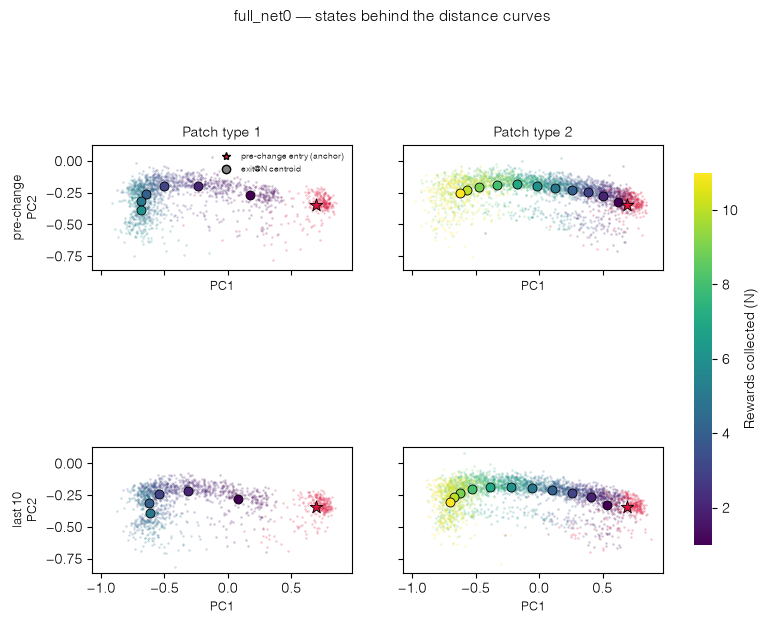

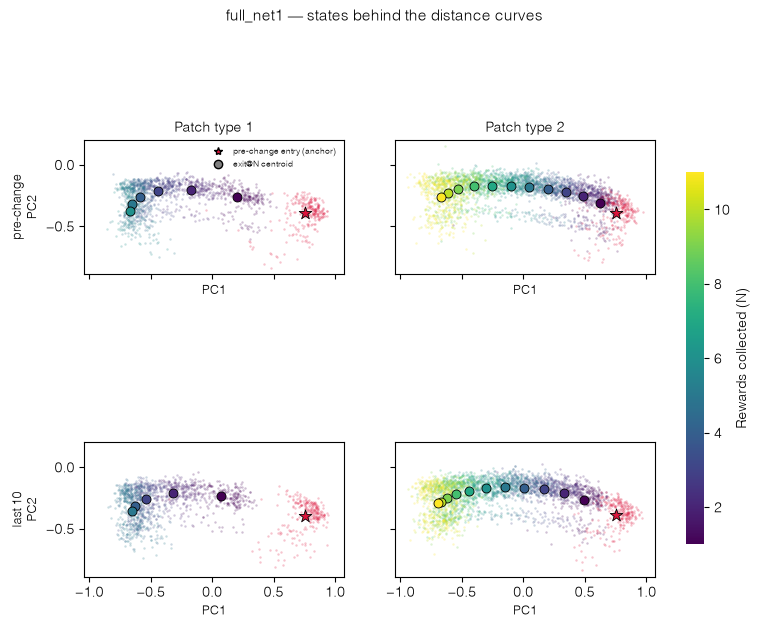

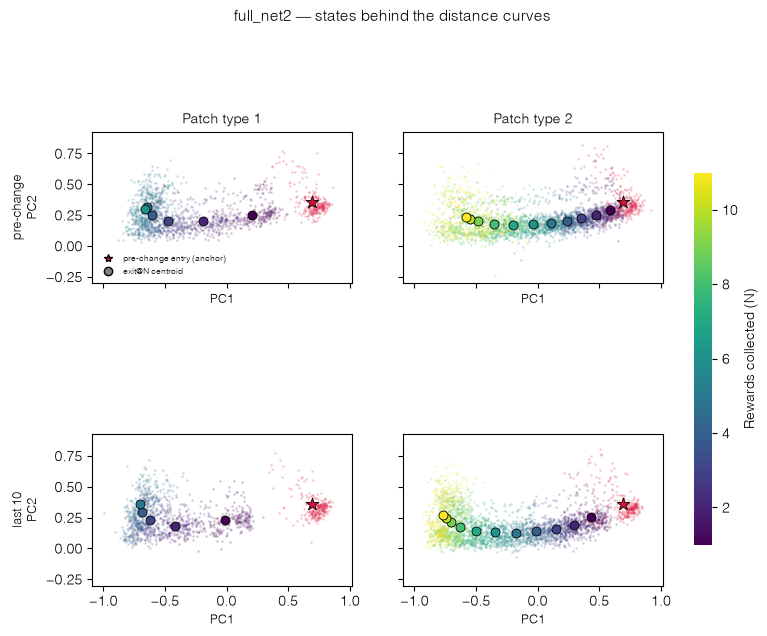

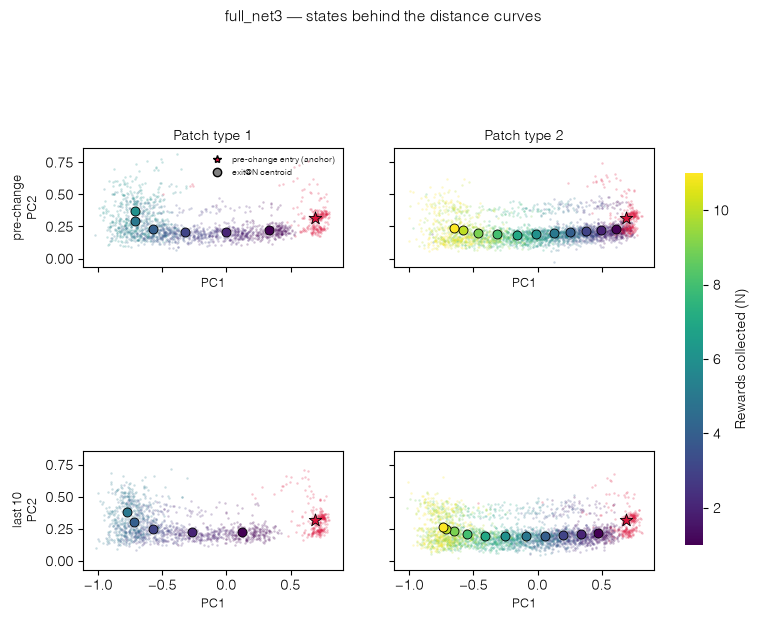

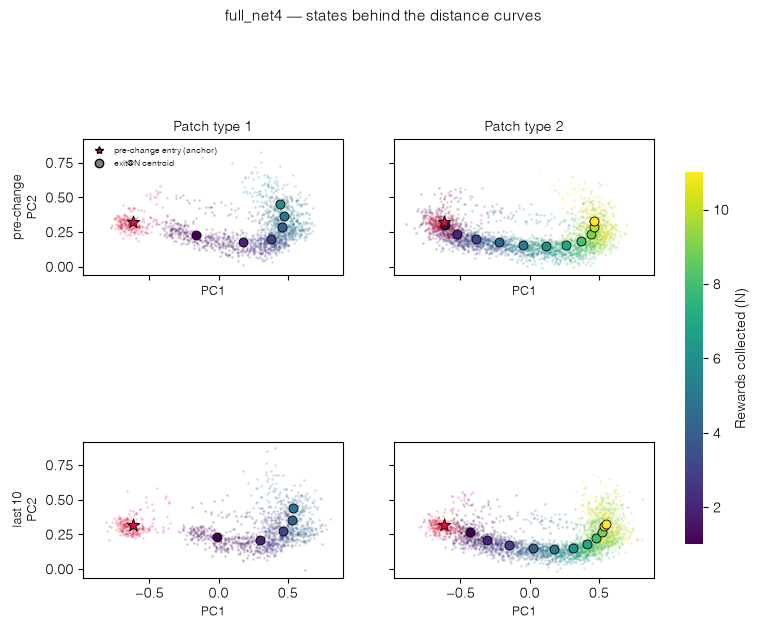

In [42]:
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D

# States behind the distance curves, in each network's own PCA (net_data[i]['pcs']).
STATES_PC_FIG_DIR = f'{FIG_ROOT}/entry_exit_states_pc'
MAX_PTS    = 250      # states drawn per group; centroids always use the full set
PC_X, PC_Y = 0, 1     # which PCs to show
_rng = np.random.default_rng(0)

for i in NETS:
    d = net_data[i]
    P = d['pcs']
    _pre = pre_change_mask(i, d)
    _windows = [('pre-change', _pre), (f'last {LAST_K}', last_k_mask(i, d))]
    _exitN = sorted({int(n) for n in d['n_pts'][d['kind_pts'] == 'exit']} - {-1})
    _gnorm = Normalize(vmin=min(_exitN), vmax=max(_exitN))

    fig, axes = plt.subplots(len(_windows), len(PATCH_TYPES),
                             figsize=(4.0 * len(PATCH_TYPES), 3.6 * len(_windows)),
                             squeeze=False, sharex=True, sharey=True)
    for r, (_wl, _wm) in enumerate(_windows):
        for c, t in enumerate(PATCH_TYPES):
            ax = axes[r][c]
            is_t = d['pt_pts'] == t
            for N in _exitN:
                m = _wm & is_t & (d['kind_pts'] == 'exit') & (d['n_pts'] == N)
                if m.sum() < MIN_SAMPLES:
                    continue
                idx = np.where(m)[0]
                if idx.size > MAX_PTS:
                    idx = _rng.choice(idx, MAX_PTS, replace=False)
                ax.scatter(P[idx, PC_X], P[idx, PC_Y], s=1, alpha=1.0,
                           color=plt.cm.cool(_gnorm(N)), linewidths=0)
                ax.scatter(*P[m][:, [PC_X, PC_Y]].mean(axis=0), s=42, marker='o',
                           color=plt.cm.cool(_gnorm(N)), edgecolors='k',
                           linewidths=0.6, zorder=5)
            # entry state for THIS window
            am = _wm & is_t & (d['kind_pts'] == 'entry')
            idx = np.where(am)[0]
            if idx.size > MAX_PTS:
                idx = _rng.choice(idx, MAX_PTS, replace=False)
            ax.scatter(P[idx, PC_X], P[idx, PC_Y], s=1, alpha=1.0,
                       color='black', linewidths=0)
            ax.scatter(*P[am][:, [PC_X, PC_Y]].mean(axis=0), s=70, marker='o',
                       color='black', edgecolors='k', linewidths=0.6, zorder=6)
            # opt-out = the pre-odor state of the site the agent SKIPS (the leave decision),
            # also taken from THIS window.
            om = _wm & is_t & (d['kind_pts'] == 'optout')
            if om.sum() >= MIN_SAMPLES:
                idx = np.where(om)[0]
                if idx.size > MAX_PTS:
                    idx = _rng.choice(idx, MAX_PTS, replace=False)
                ax.scatter(P[idx, PC_X], P[idx, PC_Y], s=1, alpha=1.0,
                           color='red', linewidths=0)
                ax.scatter(*P[om][:, [PC_X, PC_Y]].mean(axis=0), s=70, marker='o',
                           color='red', edgecolors='k', linewidths=0.6, zorder=6)
            if r == 0:
                ax.set_title(f'Patch type {t}', fontsize=10)
            if c == 0:
                ax.set_ylabel(f'{_wl}\nPC{PC_Y + 1}', fontsize=9)
            ax.set_xlabel(f'PC{PC_X + 1}', fontsize=9)
            ax.set_aspect('equal')   # equal units on both PC axes
            format_plot(ax)

    _sm = plt.cm.ScalarMappable(cmap='cool', norm=_gnorm); _sm.set_array([])
    _cb = fig.colorbar(_sm, ax=axes, label='Rewards collected (N)',
                       fraction=0.02, shrink=0.45, aspect=30)
    _cb.outline.set_visible(False)
    axes[0][0].legend(handles=[
        Line2D([], [], marker='o', ls='none', color='black', markeredgecolor='k',
               label='entry (before first site)'),
        Line2D([], [], marker='o', ls='none', color='grey', markeredgecolor='k',
               label='pre-odor, N rewards'),
        Line2D([], [], marker='o', ls='none', color='red', markeredgecolor='k',
               label='pre-odor, skipped site (leave)')],
        fontsize=6, frameon=False, loc='best')
    fig.suptitle(f'full_net{i} \u2014 states behind the distance curves', fontsize=11)
    os.makedirs(STATES_PC_FIG_DIR, exist_ok=True)
    _out = os.path.join(STATES_PC_FIG_DIR, f'states_pc_net{i}.svg')
    fig.savefig(_out, format='svg', bbox_inches='tight')
    print(f'saved {_out}')
    plt.show()


## Distance from the pre-change opt-out (patch-leave) state to the state after N rewards

The mirror of the plot above. Anchor: the centroid of the **opt-out** states from
**pre-curriculum-change** sessions only — the last inter-site travel state before the agent
actually leaves the patch. Same conventions otherwise: distances in the full 64-D hidden
space, solid = pre-change, dashed = last 10 training sessions, one panel per patch type,
one colour per network.

Because the anchor is now the leave state, the curve should *fall* as N grows: states get
closer to the leave state the more rewards have been collected.


pt1 net0     pre: N=[1, 2, 3, 4, 5, 6] n=[4726, 4709, 4600, 3754, 1500, 197]
pt1 net0  last10: N=[1, 2, 3, 4, 5] n=[5680, 5629, 5098, 2480, 280]
pt1 net1     pre: N=[1, 2, 3, 4, 5, 6] n=[4850, 4830, 4760, 3897, 1223, 81]
pt1 net1  last10: N=[1, 2, 3, 4, 5] n=[5779, 5732, 5138, 2174, 242]
pt1 net2     pre: N=[1, 2, 3, 4, 5, 6] n=[4848, 4816, 4697, 3421, 874, 85]
pt1 net2  last10: N=[1, 2, 3, 4, 5] n=[5913, 5857, 5188, 1843, 111]
pt1 net3     pre: N=[1, 2, 3, 4, 5, 6] n=[4570, 4551, 4535, 4207, 2065, 251]
pt1 net3  last10: N=[1, 2, 3, 4, 5] n=[5651, 5611, 5165, 2641, 244]
pt1 net4     pre: N=[1, 2, 3, 4, 5, 6] n=[4906, 4880, 4817, 4062, 1447, 108]
pt1 net4  last10: N=[1, 2, 3, 4, 5] n=[5704, 5654, 5065, 2055, 125]
pt2 net0     pre: N=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] n=[4642, 4637, 4630, 4621, 4615, 4605, 4588, 4511, 4135, 3236, 1972]
pt2 net0  last10: N=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] n=[5720, 5714, 5700, 5695, 5685, 5661, 5562, 5014, 3601, 1790, 571]
pt2 net1     pre: N=[1, 2, 3,

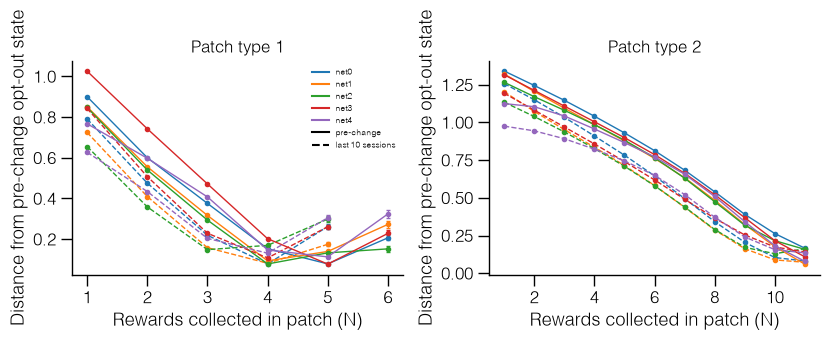

In [35]:
# Same computation as above, anchored on the pre-change opt-out (patch-leave) centroid
# instead of the entry centroid. Reuses the helpers defined in the cell above.
fig, axes = plt.subplots(1, len(PATCH_TYPES), figsize=(4.2 * len(PATCH_TYPES), 3.2),
                         squeeze=False)
for ax, t in zip(axes[0], PATCH_TYPES):
    for i in NETS:
        d = net_data[i]
        anchor = pre_change_mask(i, d)
        for exit_mask, ls, lbl in ((anchor, '-', 'pre'),
                                   (last_k_mask(i, d), '--', f'last{LAST_K}')):
            Ns, dists, ses, counts = entry_distance_curve(d, anchor, exit_mask, t,
                                                     anchor_kind='optout')
            if Ns.size:
                ax.errorbar(Ns, dists, yerr=ses, fmt=ls, marker='o', ms=3,
                            lw=1, color=f'C{i}', elinewidth=0.8, capsize=1.5)
                print(f'pt{t} net{i} {lbl:>7}: N={Ns.tolist()} n={counts.tolist()}')
    ax.set_xlabel('Rewards collected in patch (N)')
    ax.set_ylabel('Distance from pre-change pre-odor, skipped-site state')
    ax.set_title(f'Patch type {t}')
    format_plot(ax)

handles = ([Line2D([], [], color=f'C{i}', label=f'net{i}') for i in NETS]
           + [Line2D([], [], color='k', ls='-', label='pre-change'),
              Line2D([], [], color='k', ls='--', label=f'last {LAST_K} sessions')])
axes[0][0].legend(handles=handles, fontsize=6, frameon=False)
fig.tight_layout()
_dist_dir = f'{FIG_ROOT}/distance_curves'
os.makedirs(_dist_dir, exist_ok=True)
_out = os.path.join(_dist_dir, 'dist_vs_N_skipped_site_anchor.svg')
fig.savefig(_out, format='svg', bbox_inches='tight')
print(f'saved {_out}')
plt.show()


## Distance from the pre-change state after 1 reward

Third version of the same plot, anchored on the **pre-change state after 1 reward**
(`kind='exit'` at N=1) rather than on entry or opt-out. Conventions are unchanged:
full 64-D distances, delta-method error bars, solid = pre-change, dashed = last 10 sessions,
one panel per patch type, one colour per network.

The solid curve starts at exactly 0 at N=1 by construction — the anchor is that same
set of states. The dashed curve does not, and its offset at N=1 is itself informative:
it is how far the after-1-reward state moved across the curriculum change.


pt1 net0     pre: N=[1, 2, 3, 4, 5, 6] n=[4726, 4709, 4600, 3754, 1500, 197]
pt1 net0  last10: N=[1, 2, 3, 4, 5] n=[5680, 5629, 5098, 2480, 280]
pt1 net1     pre: N=[1, 2, 3, 4, 5, 6] n=[4850, 4830, 4760, 3897, 1223, 81]
pt1 net1  last10: N=[1, 2, 3, 4, 5] n=[5779, 5732, 5138, 2174, 242]
pt1 net2     pre: N=[1, 2, 3, 4, 5, 6] n=[4848, 4816, 4697, 3421, 874, 85]
pt1 net2  last10: N=[1, 2, 3, 4, 5] n=[5913, 5857, 5188, 1843, 111]
pt1 net3     pre: N=[1, 2, 3, 4, 5, 6] n=[4570, 4551, 4535, 4207, 2065, 251]
pt1 net3  last10: N=[1, 2, 3, 4, 5] n=[5651, 5611, 5165, 2641, 244]
pt1 net4     pre: N=[1, 2, 3, 4, 5, 6] n=[4906, 4880, 4817, 4062, 1447, 108]
pt1 net4  last10: N=[1, 2, 3, 4, 5] n=[5704, 5654, 5065, 2055, 125]
pt2 net0     pre: N=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] n=[4642, 4637, 4630, 4621, 4615, 4605, 4588, 4511, 4135, 3236, 1972]
pt2 net0  last10: N=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] n=[5720, 5714, 5700, 5695, 5685, 5661, 5562, 5014, 3601, 1790, 571]
pt2 net1     pre: N=[1, 2, 3,

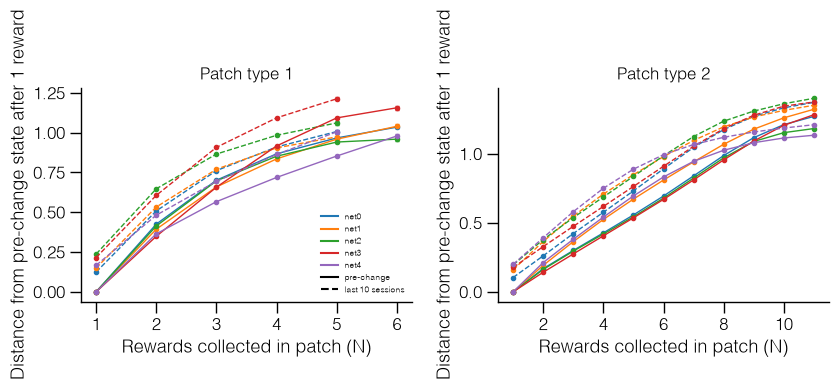

In [40]:
# Same computation, anchored on the pre-change exit state at N=1.
ANCHOR_N = 1

fig, axes = plt.subplots(1, len(PATCH_TYPES), figsize=(4.2 * len(PATCH_TYPES), 3.2),
                         squeeze=False)
for ax, t in zip(axes[0], PATCH_TYPES):
    for i in NETS:
        d = net_data[i]
        anchor = pre_change_mask(i, d)
        for exit_mask, ls, lbl in ((anchor, '-', 'pre'),
                                   (last_k_mask(i, d), '--', f'last{LAST_K}')):
            Ns, dists, ses, counts = entry_distance_curve(
                d, anchor, exit_mask, t, anchor_kind='exit', anchor_N=ANCHOR_N)
            if Ns.size:
                ax.errorbar(Ns, dists, yerr=ses, fmt=ls, marker='o', ms=3,
                            lw=1, color=f'C{i}', elinewidth=0.8, capsize=1.5)
                print(f'pt{t} net{i} {lbl:>7}: N={Ns.tolist()} n={counts.tolist()}')
    ax.set_xlabel('Rewards collected in patch (N)')
    ax.set_ylabel(f'Distance from pre-change state after {ANCHOR_N} reward')
    ax.set_title(f'Patch type {t}')
    format_plot(ax)

handles = ([Line2D([], [], color=f'C{i}', label=f'net{i}') for i in NETS]
           + [Line2D([], [], color='k', ls='-', label='pre-change'),
              Line2D([], [], color='k', ls='--', label=f'last {LAST_K} sessions')])
axes[0][0].legend(handles=handles, fontsize=6, frameon=False)
fig.tight_layout()
_dist_dir = f'{FIG_ROOT}/distance_curves'
os.makedirs(_dist_dir, exist_ok=True)
_out = os.path.join(_dist_dir, 'dist_vs_N_exit1_anchor.svg')
fig.savefig(_out, format='svg', bbox_inches='tight')
print(f'saved {_out}')
plt.show()


## How far each state moved across the curriculum change

For each network and patch type, the distance between the **pre-change** centroid and the
**last-10-session** centroid of the same state kind — i.e. how far that representation moved
over training, rather than how far apart two state kinds are. Shown for the entry
("before first site") state and the opt-out (patch-leave) state.

Markers only, with no connecting line, since the networks are independent runs and their
ordering carries no meaning.


pt1 net0   entry: 0.126  (n=4733 pre / 5694 last10)
pt1 net1   entry: 0.146  (n=4855 pre / 5792 last10)
pt1 net2   entry: 0.199  (n=4858 pre / 5923 last10)
pt1 net3   entry: 0.174  (n=4576 pre / 5664 last10)
pt1 net4   entry: 0.177  (n=4914 pre / 5709 last10)
pt1 net0  optout: 0.084  (n=4729 pre / 5689 last10)
pt1 net1  optout: 0.065  (n=4853 pre / 5787 last10)
pt1 net2  optout: 0.084  (n=4856 pre / 5919 last10)
pt1 net3  optout: 0.087  (n=4574 pre / 5657 last10)
pt1 net4  optout: 0.093  (n=4913 pre / 5704 last10)
pt2 net0   entry: 0.131  (n=4644 pre / 5720 last10)
pt2 net1   entry: 0.152  (n=4814 pre / 5830 last10)
pt2 net2   entry: 0.194  (n=4951 pre / 5866 last10)
pt2 net3   entry: 0.180  (n=4687 pre / 5541 last10)
pt2 net4   entry: 0.180  (n=4912 pre / 5811 last10)
pt2 net0  optout: 0.055  (n=4638 pre / 5717 last10)
pt2 net1  optout: 0.079  (n=4812 pre / 5819 last10)
pt2 net2  optout: 0.096  (n=4948 pre / 5860 last10)
pt2 net3  optout: 0.136  (n=4682 pre / 5538 last10)
pt2 net4  op

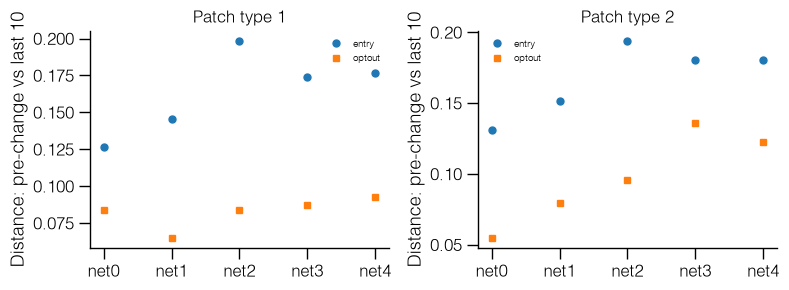

In [36]:
# Distance between the pre-change and last-10-session centroids of the SAME state kind,
# per network and patch type. Reuses the window masks defined above.
def window_shift(d, kind, mask_a, mask_b, t):
    """Distance between the `kind` centroids in two session windows."""
    X = d['states']
    sel = (d['pt_pts'] == t) & (d['kind_pts'] == kind)
    a, b = sel & mask_a, sel & mask_b
    if a.sum() < MIN_SAMPLES or b.sum() < MIN_SAMPLES:
        return np.nan, int(a.sum()), int(b.sum())
    return (float(np.linalg.norm(X[b].mean(axis=0) - X[a].mean(axis=0))),
            int(a.sum()), int(b.sum()))


# display names; 'optout' is the pre-odor state of the site the agent SKIPS (= leave)
KIND_LABEL = {'entry': 'entry (pre-first-site)', 'optout': 'pre-odor, skipped site'}
KINDS = [('entry', 'o'), ('optout', 's')]

fig, axes = plt.subplots(1, len(PATCH_TYPES), figsize=(4.0 * len(PATCH_TYPES), 3.0),
                         squeeze=False)
for ax, t in zip(axes[0], PATCH_TYPES):
    for kind, marker in KINDS:
        ys = []
        for i in NETS:
            d = net_data[i]
            v, na, nb = window_shift(d, kind, pre_change_mask(i, d), last_k_mask(i, d), t)
            ys.append(v)
            print(f'pt{t} net{i} {kind:>7}: {v:.3f}  (n={na} pre / {nb} last{LAST_K})')
        ax.plot(NETS, ys, marker=marker, ms=5, ls='none', label=KIND_LABEL.get(kind, kind))
    ax.set_xticks(list(NETS))
    ax.set_xticklabels([f'net{i}' for i in NETS])
    ax.set_ylabel(f'Distance: pre-change vs last {LAST_K}')
    ax.set_title(f'Patch type {t}')
    ax.legend(fontsize=7, frameon=False)
    format_plot(ax)
fig.tight_layout()
plt.show()


## Entry ↔ opt-out separation, before vs after the curriculum change

Distance between the **entry** centroid and the **opt-out** centroid *within* each session
window, rather than across windows. This asks how far apart the patch-entry and patch-leave
representations sit, and whether the curriculum change pulled them together or pushed them
apart. One marker per network, two windows per panel, one panel per patch type.


pt1 net0 pre-change: 1.359  (n=4733 entry / 4729 optout)
pt1 net1 pre-change: 1.373  (n=4855 entry / 4853 optout)
pt1 net2 pre-change: 1.305  (n=4858 entry / 4856 optout)
pt1 net3 pre-change: 1.369  (n=4576 entry / 4574 optout)
pt1 net4 pre-change: 1.144  (n=4914 entry / 4913 optout)
pt1 net0    last 10: 1.217  (n=5694 entry / 5689 optout)
pt1 net1    last 10: 1.258  (n=5792 entry / 5787 optout)
pt1 net2    last 10: 1.206  (n=5923 entry / 5919 optout)
pt1 net3    last 10: 1.259  (n=5664 entry / 5657 optout)
pt1 net4    last 10: 1.020  (n=5709 entry / 5704 optout)
pt2 net0 pre-change: 1.411  (n=4644 entry / 4638 optout)
pt2 net1 pre-change: 1.464  (n=4814 entry / 4812 optout)
pt2 net2 pre-change: 1.379  (n=4951 entry / 4948 optout)
pt2 net3 pre-change: 1.398  (n=4687 entry / 4682 optout)
pt2 net4 pre-change: 1.167  (n=4912 entry / 4912 optout)
pt2 net0    last 10: 1.311  (n=5720 entry / 5717 optout)
pt2 net1    last 10: 1.345  (n=5830 entry / 5819 optout)
pt2 net2    last 10: 1.295  (n=

/tmp/ipykernel_159715/315273275.py:32: UserWarning: Glyph 8596 (\N{LEFT RIGHT ARROW}) missing from font(s) Helvetica Light.
  fig.tight_layout()
/home/david.bell/work/favorably_connected_2/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8596 (\N{LEFT RIGHT ARROW}) missing from font(s) Helvetica Light.
  fig.canvas.print_figure(bytes_io, **kw)


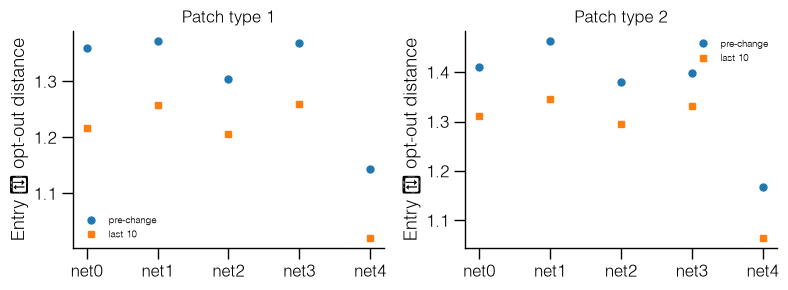

In [37]:
# Entry <-> opt-out centroid distance computed separately within each session window.
def kind_separation(d, mask, t, kind_a='entry', kind_b='optout'):
    """Distance between the kind_a and kind_b centroids within one session window."""
    X = d['states']
    sel = (d['pt_pts'] == t) & mask
    a, b = sel & (d['kind_pts'] == kind_a), sel & (d['kind_pts'] == kind_b)
    if a.sum() < MIN_SAMPLES or b.sum() < MIN_SAMPLES:
        return np.nan, int(a.sum()), int(b.sum())
    return (float(np.linalg.norm(X[b].mean(axis=0) - X[a].mean(axis=0))),
            int(a.sum()), int(b.sum()))


WINDOWS = [('pre-change', pre_change_mask, 'o'), (f'last {LAST_K}', last_k_mask, 's')]

fig, axes = plt.subplots(1, len(PATCH_TYPES), figsize=(4.0 * len(PATCH_TYPES), 3.0),
                         squeeze=False)
for ax, t in zip(axes[0], PATCH_TYPES):
    for lbl, mask_fn, marker in WINDOWS:
        ys = []
        for i in NETS:
            d = net_data[i]
            v, na, nb = kind_separation(d, mask_fn(i, d), t)
            ys.append(v)
            print(f'pt{t} net{i} {lbl:>10}: {v:.3f}  (n={na} entry / {nb} optout)')
        ax.plot(NETS, ys, marker=marker, ms=5, ls='none', label=lbl)
    ax.set_xticks(list(NETS))
    ax.set_xticklabels([f'net{i}' for i in NETS])
    ax.set_ylabel('Entry ↔ skipped-site distance')
    ax.set_title(f'Patch type {t}')
    ax.legend(fontsize=7, frameon=False)
    format_plot(ax)
fig.tight_layout()
plt.show()


## Patch trajectories in a shared PC space — pre-change vs last 10 sessions

Port of the 3-panel patch-trajectory figure from `motifs_analysis_figures.ipynb`, laid out as
**2 rows (session window) x 3 columns (patch type)** with `N_PER_TYPE` trajectories drawn per
panel, coloured by cumulative rewards in the patch.

Each network gets **one PCA fitted on hidden states pooled from both windows**, so the
pre-change and last-10 panels sit in the same activity space and are directly comparable.
Axis limits are synced across all six panels for the same reason.

The separatrix plane is the action decision boundary, which depends on the actor weights —
and those differ between the two windows. Each row therefore draws its own separatrix from
that window's checkpoint (last `step_00` checkpoint for pre-change, final checkpoint for the
last-10 row) rather than sharing one plane.


full_net0 pre-change: pt0=5, pt1=5, pt2=5
full_net0 last 10: pt0=5, pt1=5, pt2=5


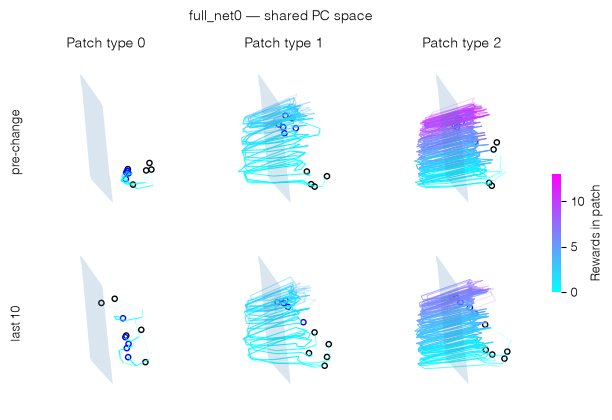

full_net1 pre-change: pt0=5, pt1=5, pt2=5
full_net1 last 10: pt0=5, pt1=5, pt2=5


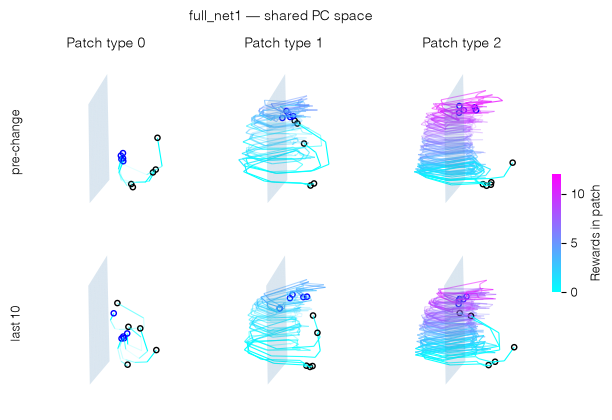

full_net2 pre-change: pt0=5, pt1=5, pt2=5
full_net2 last 10: pt0=5, pt1=5, pt2=5


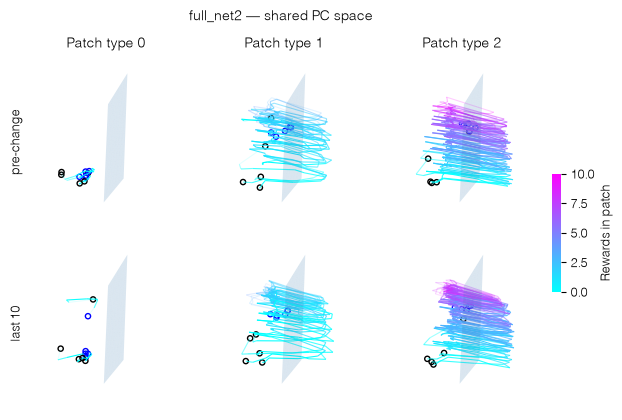

full_net3 pre-change: pt0=5, pt1=5, pt2=5
full_net3 last 10: pt0=5, pt1=5, pt2=5


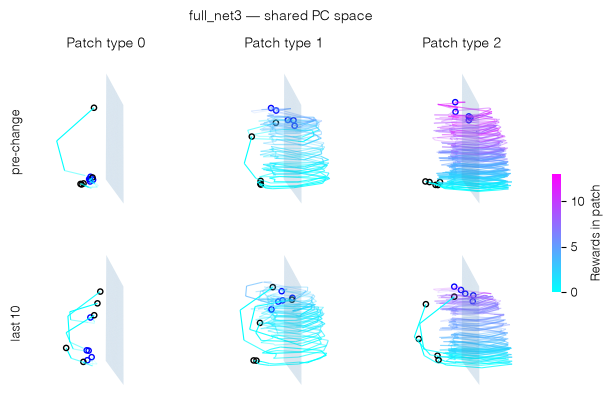

full_net4 pre-change: pt0=5, pt1=5, pt2=5
full_net4 last 10: pt0=5, pt1=5, pt2=5


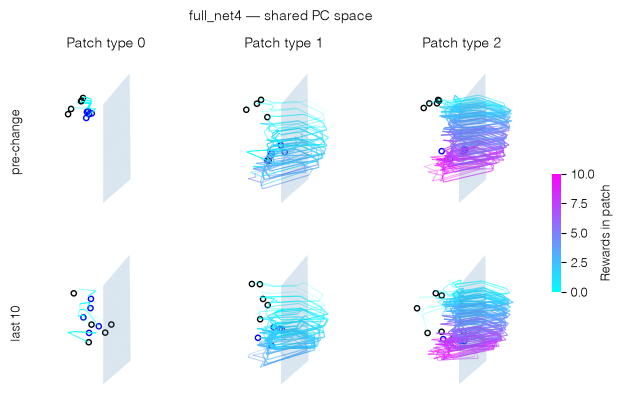

In [33]:
from matplotlib.colors import Normalize
from nb_dynamics_plotting import _depth_alpha_lc3d, add_separatrix_plane

# Patch trajectories per patch type, pre-change vs last 10 sessions, in a per-network
# shared PC space. Loads MAX_FILES_PER_WINDOW trajectory files per window per network.
N_PER_TYPE           = 5
PATCH_TYPES_3        = [0, 1, 2]
MAX_FILES_PER_WINDOW = 2      # files scanned per window; raise if a patch type comes up short
THRESHOLD            = 0.5
AZIM, ELEV, LW       = 180, -110, 0.8
_traj_cmap           = sns.color_palette(palette='cool', as_cmap=True)


def collect_patches(paths, n_per_type):
    """Up to n_per_type patch segments per patch type, plus the pooled hidden states
    (used to fit the shared PCA)."""
    recs = {t: [] for t in PATCH_TYPES_3}
    pool = []
    for p in paths:
        raw = load_trajectory_data(p)
        for e in range(len(raw)):
            d = parse_behavioral_data(raw[e])
            obs  = np.asarray(d['observations'])
            h    = np.asarray(d['actor_hidden'])
            rew  = np.asarray(d['rewards'])
            pnum = np.asarray(d['current_patch_num'])
            pool.append(h)
            padded = np.concatenate([[False], obs[:, 0] > THRESHOLD, [False]])
            diff   = np.diff(padded.astype(int))
            for s, e2 in zip(np.where(diff == 1)[0], np.where(diff == -1)[0]):
                t = int(pnum[s])
                if t in recs and len(recs[t]) < n_per_type:
                    recs[t].append((h[max(0, s - 1):e2],
                                    np.cumsum(rew[max(0, s - 1):e2]).astype(float)))
            if all(len(v) >= n_per_type for v in recs.values()):
                return recs, np.concatenate(pool, axis=0)
    return recs, np.concatenate(pool, axis=0)


for _net in NETS:
    _trajs = net_trajectories(_net)
    _pre_files = [p for p in _trajs if 'step_00' in p]
    _windows = {'pre-change': _pre_files[-MAX_FILES_PER_WINDOW:],
                f'last {LAST_K}': _trajs[-LAST_K:][-MAX_FILES_PER_WINDOW:]}

    _collected, _pools = {}, []
    for _wl, _files in _windows.items():
        _recs, _pool = collect_patches(_files, N_PER_TYPE)
        _collected[_wl] = _recs
        _pools.append(_pool)
        print(f'full_net{_net} {_wl}: ' + ', '.join(f'pt{t}={len(v)}' for t, v in _recs.items()))

    # ONE PCA per network, fitted across BOTH windows -> shared activity space
    _spca = PCA(n_components=3).fit(np.concatenate(_pools, axis=0))

    # window-appropriate weights for the separatrix
    _ck = net_checkpoints(_net)
    _win_params = {
        'pre-change': checkpoints.restore_checkpoint(
            ckpt_dir=Path([c for c in _ck if 'step_00' in c][-1]).resolve(),
            target=train_state).params,
        f'last {LAST_K}': checkpoints.restore_checkpoint(
            ckpt_dir=Path(_ck[-1]).resolve(), target=train_state).params,
    }

    _all_cum = np.concatenate([cr for r in _collected.values() for v in r.values()
                               for _, cr in v])
    _gnorm = Normalize(vmin=0, vmax=float(_all_cum.max()))

    _fig = plt.figure(figsize=(7, 4.6))
    _gs  = _fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 0.05], wspace=0.02, hspace=0.05)
    _active = []
    for _r, _wl in enumerate(_windows):
        for _c, _pt in enumerate(PATCH_TYPES_3):
            _ax = _fig.add_subplot(_gs[_r, _c], projection='3d')
            _segs_list = _collected[_wl][_pt]
            if not _segs_list:
                _ax.set_visible(False)
                continue
            _active.append((_ax, _wl))
            for _h, _cr in _segs_list:
                _pp   = _spca.transform(_h)[:, :3]
                _pts  = _pp.reshape(-1, 1, 3)
                _segs = np.concatenate([_pts[:-1], _pts[1:]], axis=1)
                _ax.add_collection3d(_depth_alpha_lc3d(
                    _segs, _traj_cmap(_gnorm(_cr[:-1])), ELEV, AZIM,
                    linewidth=LW, zorder=1))
                _ax.scatter(*_pp[0],  s=14, marker='o', facecolors='none',
                            edgecolors='black', zorder=7)
                _ax.scatter(*_pp[-1], s=14, marker='o', facecolors='none',
                            edgecolors='blue', zorder=7)
            _ax.view_init(elev=ELEV, azim=AZIM)
            _ax.set_axis_off()
            if _r == 0:
                _ax.set_title(f'Patch type {_pt}', fontsize=10)
            if _c == 0:
                _ax.text2D(-0.02, 0.5, _wl, transform=_ax.transAxes, rotation=90,
                           va='center', ha='center', fontsize=9)

    _axs = [a for a, _ in _active]
    for _g, _s in [('get_xlim3d', 'set_xlim3d'), ('get_ylim3d', 'set_ylim3d'),
                   ('get_zlim3d', 'set_zlim3d')]:
        _lo = min(getattr(a, _g)()[0] for a in _axs)
        _hi = max(getattr(a, _g)()[1] for a in _axs)
        for a in _axs:
            getattr(a, _s)(_lo, _hi)
    for a, _wl in _active:
        add_separatrix_plane(a, _win_params[_wl], _spca)

    _ax_cb = _fig.add_subplot(_gs[:, 3])
    _sm = plt.cm.ScalarMappable(cmap=_traj_cmap, norm=_gnorm); _sm.set_array([])
    _pos = _ax_cb.get_position(); _nh = _pos.height / 3
    _ax_cb.set_position([_pos.x0, _pos.y0 + _pos.height / 2 - _nh / 2, _pos.width, _nh])
    _cbar = _fig.colorbar(_sm, cax=_ax_cb, orientation='vertical', label='Rewards in patch')
    _cbar.outline.set_visible(False)
    _cbar.ax.yaxis.label.set_size(9)
    _ax_cb.tick_params(labelsize=9)
    _fig.suptitle(f'full_net{_net} \u2014 shared PC space', fontsize=10)
    plt.show()


## Consecutive centroid steps along the reward sequence

Rather than measuring everything against one fixed anchor, this walks the chain:
`||exit@1 - entry||`, then `||exit@2 - exit@1||`, `||exit@3 - exit@2||`, and so on. Each
point is therefore the step the representation takes for **one additional reward**, computed
**within** a session window — so the pre-change and after curves each describe their own
internal geometry.

Full 64-D distances, **one row per network** and one column per patch type, so each panel
shows a single network. Within a panel, blue = pre-change and red = last 10 sessions. Note that consecutive steps share patches (a patch reaching N
rewards contributes to both the N-1 and N centroids), so the error bars, which assume the two
groups are independent, are slightly conservative.


pt1 net0        pre-change: E$\leftrightarrow$1=0.652  1$\leftrightarrow$2=0.426  2$\leftrightarrow$3=0.298  3$\leftrightarrow$4=0.249  4$\leftrightarrow$5=0.191  5$\leftrightarrow$6=0.159
pt1 net0  last 10 sessions: E$\leftrightarrow$1=0.665  1$\leftrightarrow$2=0.409  2$\leftrightarrow$3=0.283  3$\leftrightarrow$4=0.241  4$\leftrightarrow$5=0.212
pt2 net0        pre-change: E$\leftrightarrow$1=0.418  1$\leftrightarrow$2=0.168  2$\leftrightarrow$3=0.138  3$\leftrightarrow$4=0.135  4$\leftrightarrow$5=0.139  5$\leftrightarrow$6=0.146  6$\leftrightarrow$7=0.159  7$\leftrightarrow$8=0.168  8$\leftrightarrow$9=0.165  9$\leftrightarrow$10=0.135  10$\leftrightarrow$11=0.103
pt2 net0  last 10 sessions: E$\leftrightarrow$1=0.441  1$\leftrightarrow$2=0.202  2$\leftrightarrow$3=0.167  3$\leftrightarrow$4=0.162  4$\leftrightarrow$5=0.164  5$\leftrightarrow$6=0.173  6$\leftrightarrow$7=0.179  7$\leftrightarrow$8=0.170  8$\leftrightarrow$9=0.151  9$\leftrightarrow$10=0.122  10$\leftrightarrow$11=0

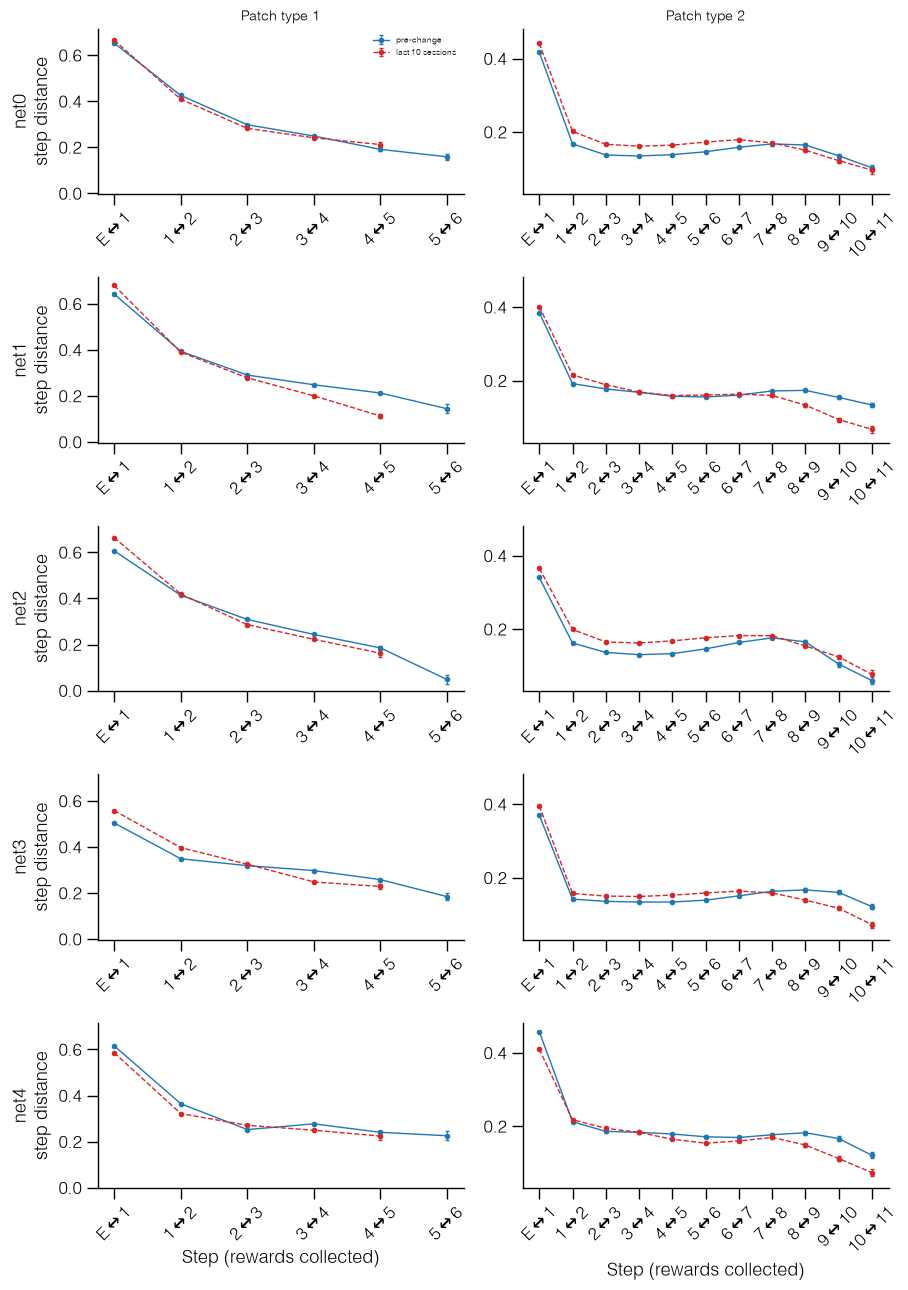

In [46]:
# Distance between CONSECUTIVE centroids along the reward sequence, within each window.
def consecutive_step_curve(d, mask, t):
    """(Ns, dists, ses, labels): ||exit@1 - entry||, ||exit@2 - exit@1||, ... for patch
    type t inside one session window."""
    X = d['states']
    is_t = (d['pt_pts'] == t) & mask
    em = is_t & (d['kind_pts'] == 'entry')
    if em.sum() < MIN_SAMPLES:
        return np.array([]), np.array([]), np.array([]), []
    prev_X = X[em]
    prev_c = prev_X.mean(axis=0)
    prev_lbl = 'E'

    Ns, dists, ses, labels = [], [], [], []
    for N in sorted({int(n) for n in d['n_pts'][d['kind_pts'] == 'exit']}):
        if N < 1:
            continue
        m = is_t & (d['kind_pts'] == 'exit') & (d['n_pts'] == N)
        if m.sum() < MIN_SAMPLES:
            continue
        B = X[m]
        diff = B.mean(axis=0) - prev_c
        dist = float(np.linalg.norm(diff))
        if dist > 0:
            u = diff / dist
            se = float(np.sqrt(np.var(prev_X @ u, ddof=1) / len(prev_X)
                               + np.var(B @ u, ddof=1) / len(B)))
        else:
            se = 0.0
        Ns.append(N); dists.append(dist); ses.append(se)
        labels.append(fr'{prev_lbl}$\leftrightarrow${N}')
        prev_X, prev_c, prev_lbl = B, B.mean(axis=0), str(N)
    return np.array(Ns), np.array(dists), np.array(ses), labels


# One row per network, one column per patch type.
WINDOW_STYLES = [(pre_change_mask, '-',  'C0', 'pre-change'),
                 (last_k_mask,     '--', 'C3', f'last {LAST_K} sessions')]

fig, axes = plt.subplots(len(NETS), len(PATCH_TYPES),
                         figsize=(4.6 * len(PATCH_TYPES), 2.6 * len(NETS)),
                         squeeze=False, sharex='col', sharey='col')
for r, i in enumerate(NETS):
    d = net_data[i]
    for c, t in enumerate(PATCH_TYPES):
        ax = axes[r][c]
        ticks, tlabels = None, None
        for mask_fn, ls, color, wl in WINDOW_STYLES:
            Ns, dists, ses, labels = consecutive_step_curve(d, mask_fn(i, d), t)
            if not Ns.size:
                continue
            ax.errorbar(Ns, dists, yerr=ses, fmt=ls, marker='o', ms=3, lw=1,
                        color=color, elinewidth=0.8, capsize=1.5, label=wl)
            if ticks is None or len(Ns) > len(ticks):
                ticks, tlabels = Ns, labels
            print(f'pt{t} net{i} {wl:>17}: ' +
                  '  '.join(f'{a}={b:.3f}' for a, b in zip(labels, dists)))
        if ticks is not None:
            ax.set_xticks(ticks)
            ax.set_xticklabels(tlabels, rotation=45, fontsize=6)
        if r == 0:
            ax.set_title(f'Patch type {t}', fontsize=10)
        if r == len(NETS) - 1:
            ax.set_xlabel('Step (rewards collected)')
        if c == 0:
            ax.set_ylabel(f'net{i}\nstep distance', fontsize=8)
        if r == 0 and c == 0:
            ax.legend(fontsize=6, frameon=False)
        format_plot(ax)
fig.tight_layout()
plt.show()
